# News_Category_Dataset
The raw data is uploaded here.

In [ ]:
import pandas as pd
df=pd.read_json("News_Category_Dataset_v3.json",lines=True)

print(df.info())
print("_"*67)
print(df["category"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209527 entries, 0 to 209526
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               209527 non-null  object        
 1   headline           209527 non-null  object        
 2   category           209527 non-null  object        
 3   short_description  209527 non-null  object        
 4   authors            209527 non-null  object        
 5   date               209527 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 9.6+ MB
None
___________________________________________________________________
category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES 

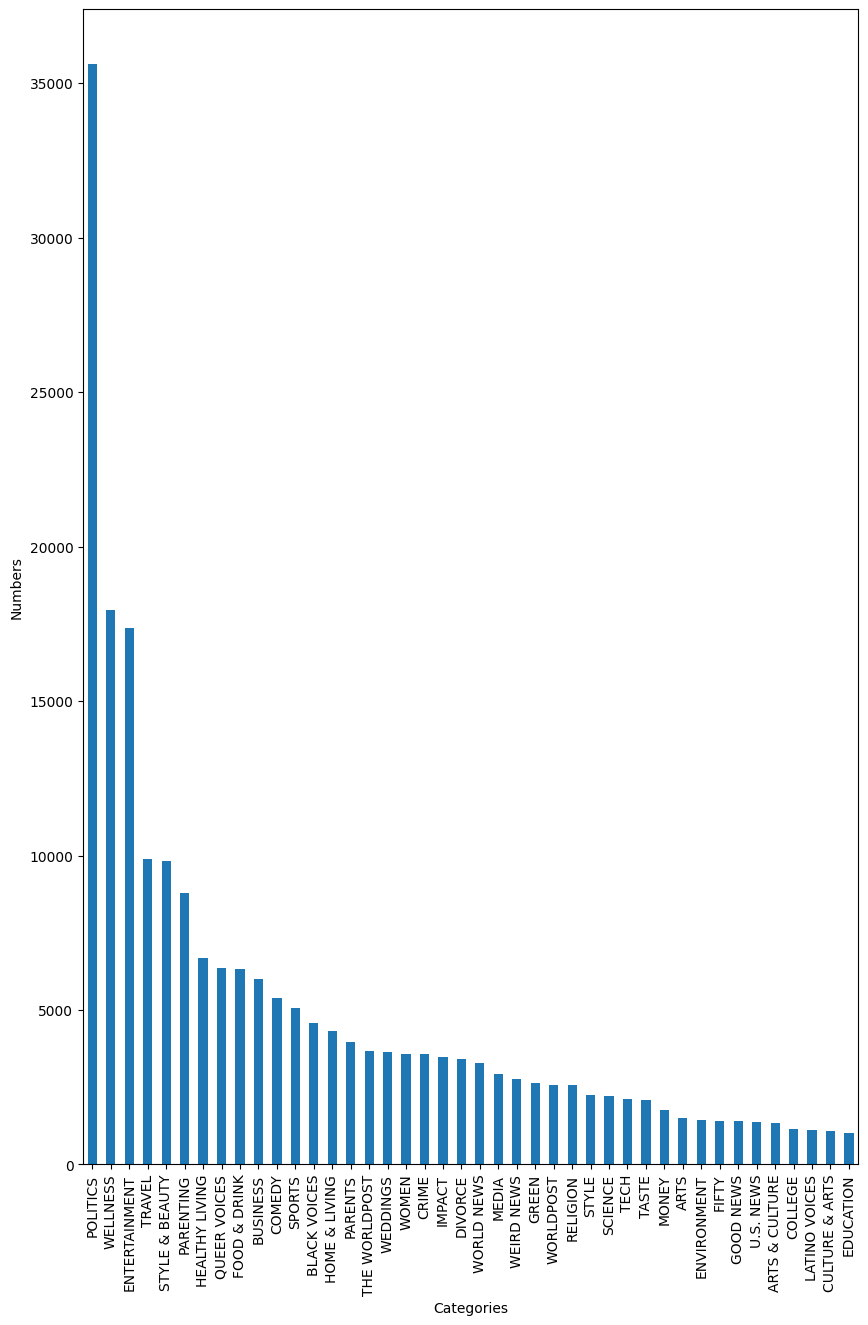

In [ ]:
import matplotlib.pyplot as plot
fig=plot.figure(figsize=(10,15))
df["category"].value_counts().plot(kind="bar")
plot.xlabel("Categories")
plot.ylabel("Numbers")
plot.show()


Duplicated datas


In [ ]:
print(df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values("headline")


13


,link,headline,category,short_description,authors,date
145141,https://www.huffingtonpost.comhttp://www.weather.com/news/science/environment/10-cities-could-run-out-water-20131212?pageno=1,10 Cities That Could Run Out Of Water - Weather.com,ENVIRONMENT,"Securing access to plentiful, renewable sources of fresh water is among the biggest struggles large cities around the world",,2013-12-15
145142,https://www.huffingtonpost.comhttp://www.weather.com/news/science/environment/10-cities-could-run-out-water-20131212?pageno=1,10 Cities That Could Run Out Of Water - Weather.com,ENVIRONMENT,"Securing access to plentiful, renewable sources of fresh water is among the biggest struggles large cities around the world",,2013-12-15
194596,https://www.huffingtonpost.comhttp://blogs.wsj.com/cio/2012/07/06/apple-removes-green-electronics-certification-from-products/,Apple Removes Green EPEAT Electronics Certification From Products,TECH,Apple has pulled its products off the U.S. government-backed registration of environmentally friendly electronics. Read more,,2012-07-07
194595,https://www.huffingtonpost.comhttp://blogs.wsj.com/cio/2012/07/06/apple-removes-green-electronics-certification-from-products/,Apple Removes Green EPEAT Electronics Certification From Products,TECH,Apple has pulled its products off the U.S. government-backed registration of environmentally friendly electronics. Read more,,2012-07-07
207208,https://www.huffingtonpost.comhttp://d.repubblica.it/english/fashion/2012/02/22/video/prada_video-865968/1/,Behind-The-Scenes Look At Prada's Workshop (VIDEO),STYLE & BEAUTY,"Exclusive worldwide and for the first time in her history, Prada opens the doors to the most secret areas of her laboratories",,2012-02-22
207207,https://www.huffingtonpost.comhttp://d.repubblica.it/english/fashion/2012/02/22/video/prada_video-865968/1/,Behind-The-Scenes Look At Prada's Workshop (VIDEO),STYLE & BEAUTY,"Exclusive worldwide and for the first time in her history, Prada opens the doors to the most secret areas of her laboratories",,2012-02-22
187329,https://www.huffingtonpost.comhttp://www.nytimes.com/2012/09/23/opinion/sunday/the-optimal-diet.html?hp,"Eating For Health, Not Weight",WELLNESS,"Almost half of Americans are on a diet -- not surprising, since two-thirds are overweight or obese, a frightening statistic",,2012-09-23
187328,https://www.huffingtonpost.comhttp://www.nytimes.com/2012/09/23/opinion/sunday/the-optimal-diet.html?hp,"Eating For Health, Not Weight",WELLNESS,"Almost half of Americans are on a diet -- not surprising, since two-thirds are overweight or obese, a frightening statistic",,2012-09-23
67901,https://www.huffingtonpost.comhttp://gizmodo.com/former-facebook-workers-we-routinely-suppressed-conser-1775461006,Former Facebook Workers: We Routinely Suppressed Conservative News,TECH,Facebook workers routinely suppressed news stories of interest to conservative readers from the social network’s influential,,2016-05-09
67923,https://www.huffingtonpost.comhttp://gizmodo.com/former-facebook-workers-we-routinely-suppressed-conser-1775461006,Former Facebook Workers: We Routinely Suppressed Conservative News,TECH,Facebook workers routinely suppressed news stories of interest to conservative readers from the social network’s influential,,2016-05-09


Dropped the duplicated datas

In [ ]:
df=df.drop_duplicates()
df.duplicated().sum()
df[df.duplicated(keep=False)].sort_values("headline")

,link,headline,category,short_description,authors,date


Length of the headlines


In [ ]:
head_len=df["headline"].str.len()
head_len.describe()
print(head_len)

0         76
1         89
2         69
3         56
4         77
          ..
209522    58
209523    69
209524    99
209525    53
209526    56
Name: headline, Length: 209514, dtype: int64


Creating the outlier

In [ ]:
Q1 = head_len.quantile(0.25)
Q3 = head_len.quantile(0.75)
IQR=Q3-Q1
lower_boundary= Q1-(1.5*IQR)
Higher_boundary= Q3+(1.5*IQR)
print("lower boundary,Q1:", lower_boundary)
print("Higher boundary,Q3:", Higher_boundary)


lower boundary,Q1: 8.5
Higher boundary,Q3: 108.5


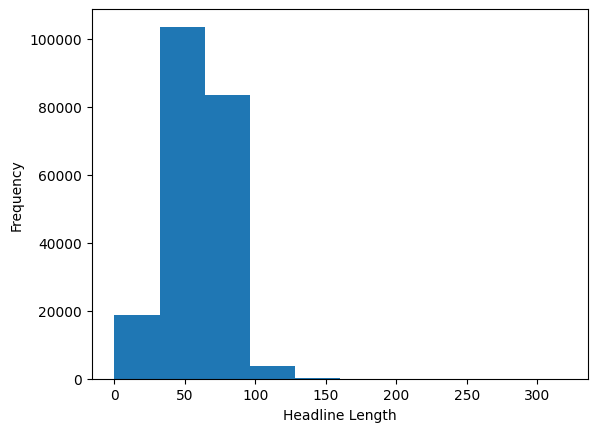

In [ ]:
import numpy as np
leng=np.array(head_len)
plot.hist(leng)
plot.xlabel("Headline Length")
plot.ylabel("Frequency")
plot.show()

In [ ]:
print((head_len<lower_boundary).sum())
print((head_len>Higher_boundary).sum())

218
902


Checking the Outliers

In [ ]:
outliers=df[(head_len<lower_boundary)|(head_len>Higher_boundary)]["headline"]
outliers

,headline
4238,"Postmaster General Louis DeJoy Evades Responsibility For Major Post Office Delays, Refuses to Reverse Changes"
5506,Iran's Supreme Leader Ayatollah Ali Khamenei: 'Harsh Retaliation Is Waiting' For U.S. After General's Assassination
8106,Devin Nunes Is Infamous For Sabotaging The Trump-Russia Investigation. His Opponent Andrew Janz Is Running On Water.
8871,A Mostly Non-Christian Militia Won 2 Of Iraqi Christians' Parliamentary Seats. Now Christians Want Trump To Intervene.
9451,'A LITTLE EXTORTION-Y'...This Guy Figured Out What Stormy Daniels' Old Lawyer ACTUALLY DOES — And It's Not Pretty!
...,...
209131,CFDA's 'The Fashion Fund' On Hulu: Diane Von Furstenberg And Joseph Altuzarra Talk About Fashion's Most Coveted Prize (VIDEO)
209219,The Couple That Argues Together Stays Together: How Bickering Could Be The Key To A Long And Healthy Marriage
209296,"Jessica Hoppe, Blogger Behind 'Having It All' Has Become That Girl Who Shows Baby Pictures At Parties (PHOTOS)"
209483,"Jon Stewart, Dead Kennedys Fan? '80s Photo Apparently Shows Young 'Daily Show' Host At Punk Show (UPDATE: OK, Probably Not)"


In [ ]:
outliers.sample(30)

,headline
153061,"Marianne Williamson Talks Transcendental Meditation, Enlightenment And Shoulder Pads In ORIGIN Magazine (PHOTOS)"
112295,Autism Without Fear: We Raise Money for Autism Research... But Not for Our Kids' Schools and Service Agencies?
161133,"Janelle Monae Releases 'Dance Apocalyptic,' Discusses New Album And How To 'Maximize Your Full Experience' With Her Music"
22138,Rewriting History The Trump Way: Trump Undermines The Rule Of Law By Supporting Sheriff Arpaio's Bid To Expunge His Criminal Record
191442,"Rachel Ashwell's Shabby Chic Design Inspiration: London Olympic Games, Downton Abbey And Her British Heritage (PHOTOS)"
99118,"Amazon's Same-Day Delivery Service Taking Hits From Unreliable Third Party Couriers and Other, Faster Options"
161269,"Celebrities With Green Homes: Jessica Alba, Lisa Ling and Four Other A-Listers With Eco-Friendly Houses (PHOTOS)"
206871,"Seth Rogen Independent Spirit Awards Monologue: Host Blasts Brett Ratner, Chris Brown And Mel Gibson In Hilarious Opening"
129360,"Kerry: It Would Have Been 'Offensive' To Leave Bergdahl With People Who Would 'Torture Him, Cut Off His Head'"
185528,I Lost Weight: Tom Dioguardi Made Over His Eating Habits With The Help Of A Dietitian Friend And Lost 100 Pounds


In [ ]:
print(df.loc[109100])
print("*"*20)
print(df.loc[19578])
print(df.loc[197505]["short_description"])

link                 https://www.huffingtonpost.com/entry/disney-ceo-iger-readies-m_b_6520290.html
headline                                                                                          
category                                                                                  BUSINESS
short_description                                                                                 
authors                                        Gary Snyder, ContributorWriter and Media Strategist
date                                                                           2015-01-25 00:00:00
Name: 109100, dtype: object
********************
link                 https://www.huffingtonpost.com/entry/what-if-afghanistan-iraq-september-11_us_5a1b6de7e4b064948075419c
headline                                                                                                           What If?
category                                                                                                     

Examining the Outliers Headlines



*   Row 11503, 126860 they contains only one words which is not really usefull
*   Long headlines actually usefull



In [ ]:
pd.set_option('display.max_colwidth', None)
outliers.sample(n=min(25,len(outliers)),random_state=42)


,headline
93006,HuffPost What's Working Honor Roll: Anonymous Messaging App Provides Suicide Intervention On College Campuses
37682,Trinity Lutheran v. Comer: 7 Things To Know About A SCOTUS Preschool Case With Big School Choice Implications
190218,"EXCLUSIVE: David’s Bridal Agrees To Be Acquired By Private-equity Firm Clayton, Dubilier & Rice For $900M - NYPOST.com"
199317,"Nicole Scherzinger Works High Slit At 'Men In Black 3' Premiere, Nearly Suffers Wardrobe Malfunction (PHOTOS)"
131582,'I Decide:' A Campaign Calling on World Leaders to Put Sexual and Reproductive Health and Rights at the Heart of Global Development
188295,Small Space Living: Ron Barth From Resource Furniture Shares The Benefits Of Adjusting Your Home To Your Needs
156714,"Walking the Middle Path: If You Are Out of Balance in One Area of Your Life, You Are Out of Balance in Every Area"
96875,"Kavala, Thasos, and the Joys of Off-Season Travel: Natterings From Northern Greece on the Looney Front, Part 2"
47174,"No, Donald Trump Wishing Happy New Year To His 'Many Enemies' Is In No Way the Same As Hillary Clinton's 'Basket Of Deplorables'"
100597,Young and Entrepreneurial: Brian Clark's Transformation From General Electric IT Guy to Serial Hackathon Winner and Entrepreneur


In [ ]:
# Count words in each headline
df["word_count"] = df["headline"].str.split().str.len()

# Examine the distribution
print(df["word_count"].describe())

# Count headlines by word count
print(df["word_count"].value_counts().sort_index().head(15))

count    209514.000000
mean          9.600762
std           3.068503
min           0.000000
25%           8.000000
50%          10.000000
75%          12.000000
max          44.000000
Name: word_count, dtype: float64
word_count
0         6
1       256
2      1428
3      3333
4      6072
5      9234
6     13273
7     17418
8     22261
9     26335
10    28151
11    26390
12    21098
13    14743
14     9012
Name: count, dtype: int64


In [ ]:
# Counted headlines containing fewer than 1 words
short_headlines = df[
    df["headline"].str.split().str.len() < 1
]

print("Number of short headlines:", len(short_headlines))

short_headlines["headline"].sample(
    n=min(20, len(short_headlines)),
    random_state=42
)

Number of short headlines: 6


,headline
90944,
95567,
122145,
103675,
110153,
109100,


In [ ]:
print(df.loc[90944])
print(df.loc[95567])
print(df.loc[122145])
print(df.loc[103675])

link                                             https://www.huffingtonpost.com/entry/lincoln-20_b_8023742.html
headline                                                                                                       
category                                                                                               POLITICS
short_description                                                                                              
authors              Robert Moran, ContributorRobert Moran leads Brunswick Insight, and writes and speaks on...
date                                                                                        2015-08-22 00:00:00
word_count                                                                                                    0
Name: 90944, dtype: object
link                                                                                                                                 https://www.huffingtonpost.com/entry/post_9671_b_7683632

In [ ]:
#deleting the empty headlines

df = df[
    df["headline"].notna()
    & df["headline"].str.strip().ne("")
].copy()

In [ ]:
# Count words in each headline
df["word_count"] = df["headline"].str.split().str.len()

# Examine the distribution
print(df["word_count"].describe())

# Count headlines by word count
print(df["word_count"].value_counts().sort_index().head(15))

count    209508.000000
mean          9.601037
std           3.068116
min           1.000000
25%           8.000000
50%          10.000000
75%          12.000000
max          44.000000
Name: word_count, dtype: float64
word_count
1       256
2      1428
3      3333
4      6072
5      9234
6     13273
7     17418
8     22261
9     26335
10    28151
11    26390
12    21098
13    14743
14     9012
15     5175
Name: count, dtype: int64


In [ ]:
# Count headlines containing fewer than 2 words
short_headlines = df[
    df["headline"].str.split().str.len() < 2
]

print("Number of short headlines:", len(short_headlines))

short_headlines[
    ["headline", "short_description"]
].sample(
    n=min(20, len(short_headlines)),
    random_state=42
)

Number of short headlines: 256


,headline,short_description
190205,Recipes,"Both of you seem to be confused concerning what a ""meal"" is. Meals aren't supposed to be punishment, they are supposed to be delicious."
37983,Anti-Lent,"Even though I was not raised Catholic, I always enjoyed the idea of giving something up for Lent. I remember viewing it as"
119444,Praying,"It's the Jewish new year. Big holiday. Obscene amounts of food. Long hours in the synagogue. This year, I did something different. Instead of using the synagogue prayer book designated for the holiday, I took my own prayer book."
177307,Legacies,"Last week, as I thought about 2013 resolutions and reflected on the events of 2012, I realized that I am often so consumed with work and bills (the ""reason"" I have to work) that I neglect the ""real"" reasons that I have to work -- my family and myself."
130417,Frozen,"Learning to love technology, to embrace it and use it well, may involve early crashing into each other, but in the long run, it can be a great tool of connection."
166905,Inspiration,"""I turn 100 on August 5! That's something to be excited about! Thank you for your help with the hill, young man."" As he started to walk away, I had to smile myself, because initially I had thought that I was the one doing the good deed of the day."
201297,Kissing,"Our human makeup fundamentally consists of vibration, making the brain resonate with other vibrations it encounters such"
158292,Grief,"Trying to make sense of a father and son dying, trying to fit that into my understanding of how the universe is operating... my understanding of the Dharma... my understanding of my dharma... A complete mystery. And for me also a tragedy. So today I went to yoga class drunk."
47536,#BlackMenLove,I once asked men to #TwitpicYourFlowerCrown on Twitter. It started out as me poking fun at the all too popular flower crown
94996,Love?,"One may label it 'loving' all day long, profess it from the rooftops and paint it across the sky, but love it is not. Love does not exist in a dark cave of longing and desperation. Those feelings are the offspring of fear."


In [ ]:
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>

Checking duplicated files again

In [ ]:
#Exact duplicate rows
print("Full-row duplicates:", df.duplicated().sum())

Full-row duplicates: 0


In [ ]:
#Duplicate headlines
print("Duplicate headlines:",
      df.duplicated(subset=["headline"]).sum())
# print(
#     duplicate_headlines[
#         ["headline", "category", "short_description"]
#     ].head(20).to_string(index=False)
# )

Duplicate headlines: 1513


In [ ]:
print("Repeated headline rows:",
      df.duplicated(subset=["headline"]).sum())

print("Unique headline values:",
      df["headline"].nunique())

Repeated headline rows: 1513
Unique headline values: 207995


In [ ]:
# Find headlines associated with multiple categories
category_counts = (
    df.groupby("headline")["category"]
      .nunique()
)

conflicting_headlines = category_counts[
    category_counts > 1
]

print("Headlines with conflicting categories:",
      len(conflicting_headlines))

Headlines with conflicting categories: 102


In [ ]:
df[
    df["headline"].isin(conflicting_headlines.index)
][["headline", "category", "short_description"]].head(20)

,headline,category,short_description
7645,Here Are The Movies Coming To Netflix This Week,HOME & LIVING,The best Netflix movie of 2018 debuts this week.
8457,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Netflix debuts its disaster movie of the month.
8969,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,"You have a few options this week, including a new Gillian Jacobs movie."
9303,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Surprise! Netflix adds a pretty good sci-fi movie.
9685,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,This low-budget horror flick could be for you.
10078,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Is this finally the week that Netflix debuts a good sci-fi thriller?
18333,Gingerbread Dessert Recipes For The Best Holiday Baking,TASTE,It's beginning to feel a lot like Christmas.
32378,Why We March,BLACK VOICES,"Tomorrow morning, a diverse coalition of North Texans will gather in downtown Dallas at the historic St. Paul United Methodist"
33649,How Successful People Stay Calm,BUSINESS,The ability to manage your emotions and remain calm under pressure has a direct link to your performance.
34663,Hassan Rouhani's Economic Legacy May Be His Key To Winning A Second Term,WORLD NEWS,"Shahram Akbarzadeh, Deakin University Today’s presidential election in Iran had turned into a vote of confidence for President"


Many news with same headlines are in different categories. SO I have deleted the duplicated headlines with same categories


In [ ]:
df.drop_duplicates(
    subset=["headline", "category"],
    keep="first",
    inplace=True
)

In [ ]:
print(
    "Remaining duplicate headline-category pairs:",
    df.duplicated(
        subset=["headline", "category"]
    ).sum()
)

Remaining duplicate headline-category pairs: 0


In [ ]:
category_count = (
    df.groupby("headline")["category"].nunique()
)

conflicting_headlines = category_count[
    category_count > 1
]

print("Conflicting headlines:", len(conflicting_headlines))
print("Current dataset shape:", df.shape)

Conflicting headlines: 102
Current dataset shape: (208102, 7)


In [ ]:
df[
    df["headline"].isin(conflicting_headlines.index)
][["headline", "category", "short_description"]].head(20)

,headline,category,short_description
7645,Here Are The Movies Coming To Netflix This Week,HOME & LIVING,The best Netflix movie of 2018 debuts this week.
8457,Here Are The Movies Coming To Netflix This Week,ENTERTAINMENT,Netflix debuts its disaster movie of the month.
18333,Gingerbread Dessert Recipes For The Best Holiday Baking,TASTE,It's beginning to feel a lot like Christmas.
32378,Why We March,BLACK VOICES,"Tomorrow morning, a diverse coalition of North Texans will gather in downtown Dallas at the historic St. Paul United Methodist"
33649,How Successful People Stay Calm,BUSINESS,The ability to manage your emotions and remain calm under pressure has a direct link to your performance.
34663,Hassan Rouhani's Economic Legacy May Be His Key To Winning A Second Term,WORLD NEWS,"Shahram Akbarzadeh, Deakin University Today’s presidential election in Iran had turned into a vote of confidence for President"
34881,Hassan Rouhani's Economic Legacy May Be His Key To Winning A Second Term,THE WORLDPOST,"Mohammad Ali Marizad/Tasnim News Agency/Wikipedia, CC BY-NC Shahram Akbarzadeh, Deakin University Today’s presidential"
47078,Coming Home,WOMEN,
47755,The Real History Of Hanukkah Is More Complicated Than You Thought,POLITICS,"What do you really know about the ""festival of lights""?"
50108,Dear President Obama,QUEER VOICES,"Dear President Obama, This week I watched you place the Presidential Medal of Freedom on Ellen DeGeneres as she struggled"


In [ ]:
#Missing values
print(df.isnull().sum())

link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
word_count           0
dtype: int64






*  There is no duplicated Headline-Category pairs
*  Conflicting headline-Category pairs: 102
* There is no more missing values in any columns

Bar Plot after data cleanisng


*   Politics have the higher frequency of datas
*   Education has the lower frequency of datas






category
POLITICS          35478
WELLNESS          17896
ENTERTAINMENT     17321
TRAVEL             9875
STYLE & BEAUTY     9330
PARENTING          8740
HEALTHY LIVING     6684
QUEER VOICES       6337
FOOD & DRINK       6335
BUSINESS           5979
COMEDY             5343
SPORTS             5076
BLACK VOICES       4574
HOME & LIVING      4214
PARENTS            3890
THE WORLDPOST      3662
WEDDINGS           3594
CRIME              3557
IMPACT             3480
WOMEN              3457
DIVORCE            3420
WORLD NEWS         3294
MEDIA              2941
WEIRD NEWS         2777
GREEN              2617
WORLDPOST          2578
RELIGION           2568
STYLE              2246
SCIENCE            2204
TASTE              2095
TECH               2049
MONEY              1754
ARTS               1509
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ENVIRONMENT        1372
ARTS & CULTURE     1338
COLLEGE            1144
LATINO VOICES      1130
CULTURE & ARTS     1054
EDUCATI

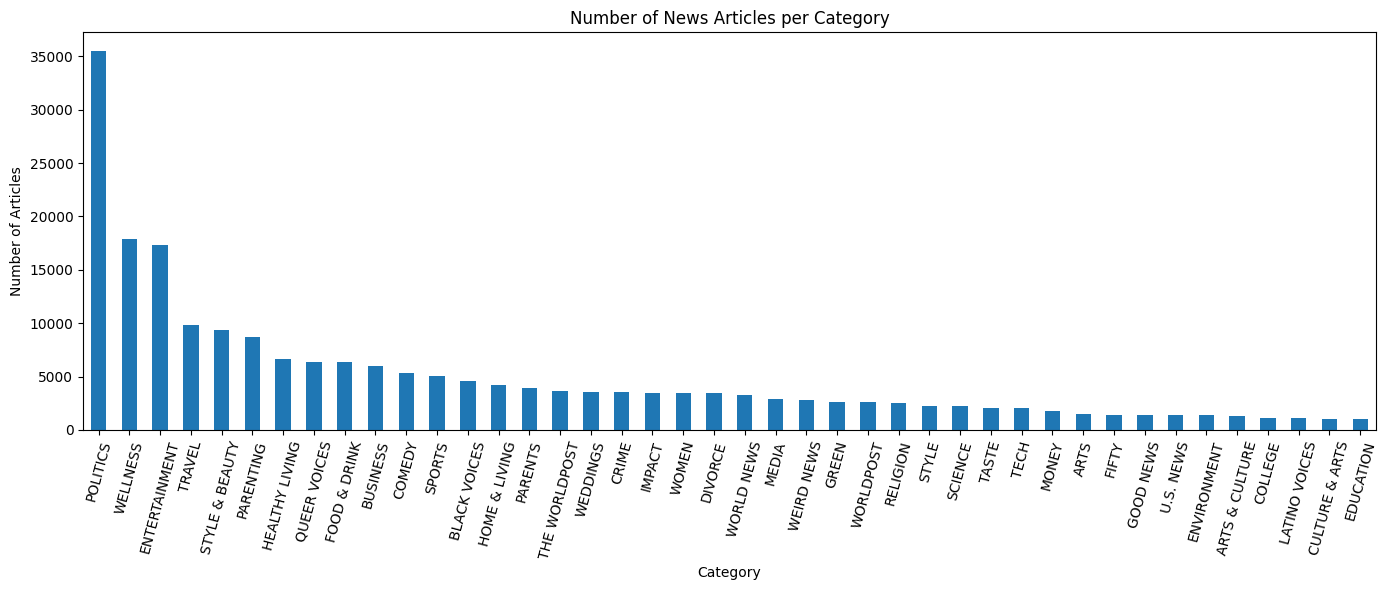

In [ ]:
import matplotlib.pyplot as plt

category_counts = df["category"].value_counts()

print(category_counts)

category_counts.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Number of News Articles per Category")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
#Lowercasing all the Headlines and Descriptions
df["lower_headlines"]=df["headline"].str.lower()
df["lower_description"]=df['short_description'].str.lower()
df["category"] = df["category"].str.upper()

In [ ]:
df[[
    "headline",
    "lower_headlines",
    "short_description",
    "category",
    "lower_description"
]].head(10)

,headline,lower_headlines,short_description,category,lower_description
0,Over 4 Million Americans Roll Up Sleeves For Omicron-Targeted COVID Boosters,over 4 million americans roll up sleeves for omicron-targeted covid boosters,Health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the U.S. ordered for the fall.,U.S. NEWS,health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the u.s. ordered for the fall.
1,"American Airlines Flyer Charged, Banned For Life After Punching Flight Attendant On Video","american airlines flyer charged, banned for life after punching flight attendant on video","He was subdued by passengers and crew when he fled to the back of the aircraft after the confrontation, according to the U.S. attorney's office in Los Angeles.",U.S. NEWS,"he was subdued by passengers and crew when he fled to the back of the aircraft after the confrontation, according to the u.s. attorney's office in los angeles."
2,23 Of The Funniest Tweets About Cats And Dogs This Week (Sept. 17-23),23 of the funniest tweets about cats and dogs this week (sept. 17-23),"""Until you have a dog you don't understand what could be eaten.""",COMEDY,"""until you have a dog you don't understand what could be eaten."""
3,The Funniest Tweets From Parents This Week (Sept. 17-23),the funniest tweets from parents this week (sept. 17-23),"""Accidentally put grown-up toothpaste on my toddler’s toothbrush and he screamed like I was cleaning his teeth with a Carolina Reaper dipped in Tabasco sauce.""",PARENTING,"""accidentally put grown-up toothpaste on my toddler’s toothbrush and he screamed like i was cleaning his teeth with a carolina reaper dipped in tabasco sauce."""
4,Woman Who Called Cops On Black Bird-Watcher Loses Lawsuit Against Ex-Employer,woman who called cops on black bird-watcher loses lawsuit against ex-employer,Amy Cooper accused investment firm Franklin Templeton of unfairly firing her and branding her a racist after video of the Central Park encounter went viral.,U.S. NEWS,amy cooper accused investment firm franklin templeton of unfairly firing her and branding her a racist after video of the central park encounter went viral.
5,Cleaner Was Dead In Belk Bathroom For 4 Days Before Body Found: Police,cleaner was dead in belk bathroom for 4 days before body found: police,"The 63-year-old woman was seen working at the South Carolina store on Thursday. She was found dead Monday after her family reported her missing, authorities said.",U.S. NEWS,"the 63-year-old woman was seen working at the south carolina store on thursday. she was found dead monday after her family reported her missing, authorities said."
6,Reporter Gets Adorable Surprise From Her Boyfriend While Live On TV,reporter gets adorable surprise from her boyfriend while live on tv,"""Who's that behind you?"" an anchor for New York’s PIX11 asked journalist Michelle Ross as she finished up an interview.",U.S. NEWS,"""who's that behind you?"" an anchor for new york’s pix11 asked journalist michelle ross as she finished up an interview."
7,Puerto Ricans Desperate For Water After Hurricane Fiona’s Rampage,puerto ricans desperate for water after hurricane fiona’s rampage,More than half a million people remained without water service three days after the storm lashed the U.S. territory.,WORLD NEWS,more than half a million people remained without water service three days after the storm lashed the u.s. territory.
8,How A New Documentary Captures The Complexity Of Being A Child Of Immigrants,how a new documentary captures the complexity of being a child of immigrants,"In ""Mija,"" director Isabel Castro combined music documentaries with the style of ""Euphoria"" and ""Clueless"" to tell a more nuanced immigration story.",CULTURE & ARTS,"in ""mija,"" director isabel castro combined music documentaries with the style of ""euphoria"" and ""clueless"" to tell a

In [ ]:
# Check which headlines contain URLs
url_mask = df["lower_description"].str.contains(
    r"https?://|www\.",
    regex=True,
    na=False
)

# Count matching headlines
print(url_mask.sum())

# Display some matching headlines
print(df.loc[url_mask, "short_description"].head(10))

171
9763                                                                                                                           Awww.
18682                                                                                                                          Ewww.
22114                                                                                                                          Awww.
23086                                                                                                                        Awwwww.
25330    1. Call your representatives. You can find who you’re representatives are at https://whoismyrepresentative.com/ If you want
31791       5. Pack Less. My favorite travel writer, Rick Steves, https://www.ricksteves.com says there are travelers who pack light
36260                                                                                                                          Ewww.
43536                                                            

In [ ]:
import re

def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)

df["headline_clean"] = df["lower_headlines"].apply(remove_urls)

df["description_clean"] = df["lower_description"].apply(remove_urls)

In [ ]:
print(df.loc[94420, "headline_clean"])
print(df.loc[94420, "description_clean"])

wendy williams announces 12-city ‘sit down tour’ read more at  williams announces 12-city ‘sit down tour’ read more at 
wendy williams is about to take her proverbial “purple chair” to a city near you this summer.


# Text Quality and Category-wise Patterns



## 1. Check missing and empty descriptions


In [ ]:
# Missing values (NaN)
print("Missing descriptions:", df["short_description"].isna().sum())

# Empty or whitespace-only descriptions
description_text = df["short_description"].fillna("").astype(str).str.strip()
empty_description_mask = description_text.eq("")

print("Empty/whitespace-only descriptions:", empty_description_mask.sum())
print("Percentage of rows with empty descriptions:",
      round(empty_description_mask.mean() * 100, 2), "%")

# Inspect a few examples with empty descriptions
df.loc[empty_description_mask, ["headline", "short_description", "category"]].head(10)

Missing descriptions: 0
Empty/whitespace-only descriptions: 19603
Percentage of rows with empty descriptions: 9.42 %


,headline,short_description,category
20773,The Big Blue Wave,,COMEDY
21523,"Inside Rukban Camp, One Of Syria’s Most Desperate Settlements",,WORLD NEWS
22793,Syrian Refugees Return From Lebanon Only To Flee War Yet Again,,WORLD NEWS
32223,Your Guide To The Best BBQ In St. Louis According to Zagat,,TASTE
34488,The Bechdel Test,,COMEDY
35584,Note: This content has been removed.,,WOMEN
43295,"Love Needs To Be Remembered, Restored and Renewed",,HEALTHY LIVING
43296,A New American Strategy in the Middle East,,WORLDPOST
43297,A Price On Carbon Is Neither Liberal Nor Conservative. It's Just Practical,,GREEN
43298,"Geoff Cowan, Former Head of Voice of America, Stresses the Need for a Strong Press in the Trump Age",,POLITICS


## 2. Compare headline and description lengths


In [ ]:
# Create length columns without changing the original text columns
df["headline_char_count"] = df["headline"].fillna("").astype(str).str.len()
df["headline_word_count"] = df["headline"].fillna("").astype(str).str.split().str.len()
df["description_char_count"] = df["short_description"].fillna("").astype(str).str.len()
df["description_word_count"] = df["short_description"].fillna("").astype(str).str.split().str.len()

display(df[[
    "headline_char_count", "headline_word_count",
    "description_char_count", "description_word_count"
]].describe().round(2))

,headline_char_count,headline_word_count,description_char_count,description_word_count
count,208102.00,208102.00,208102.00,208102.00
mean,58.47,9.61,113.87,19.61
std,18.79,3.07,79.11,13.88
min,2.00,1.00,0.00,0.00
25%,46.00,8.00,59.00,10.00
50%,60.00,10.00,120.00,19.00
75%,71.00,12.00,134.00,24.00
max,320.00,44.00,1392.00,241.00


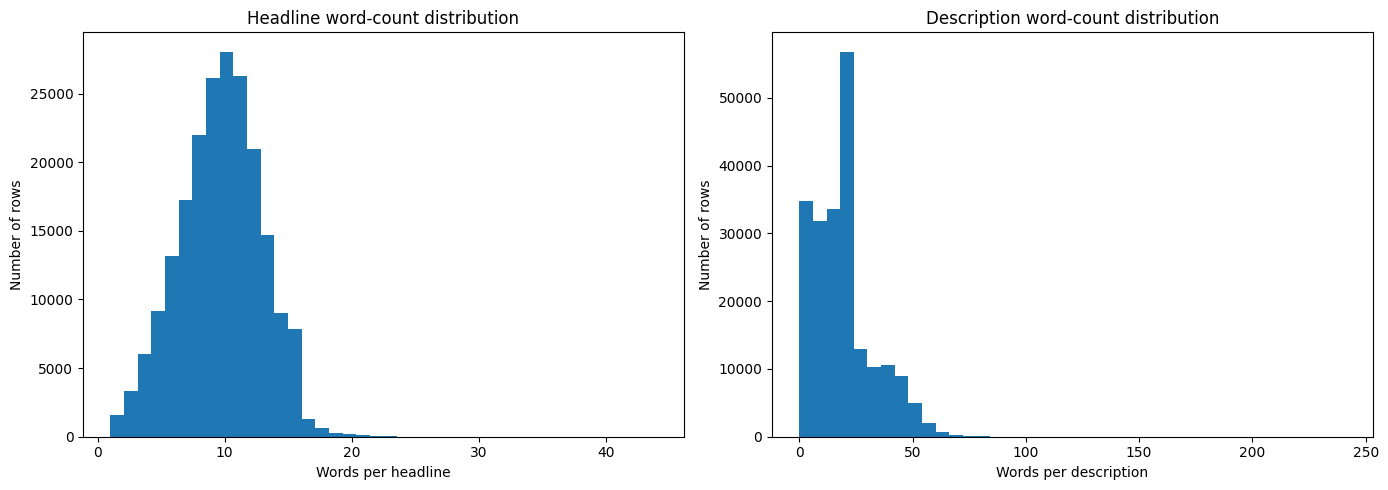

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["headline_word_count"], bins=40)
axes[0].set_title("Headline word-count distribution")
axes[0].set_xlabel("Words per headline")
axes[0].set_ylabel("Number of rows")

axes[1].hist(df["description_word_count"], bins=40)
axes[1].set_title("Description word-count distribution")
axes[1].set_xlabel("Words per description")
axes[1].set_ylabel("Number of rows")

plt.tight_layout()
plt.show()

## 3. Compare text length across categories


In [ ]:
category_text_stats = (
    df.groupby("category")
      .agg(
          article_count=("headline", "size"),
          median_headline_words=("headline_word_count", "median"),
          median_description_words=("description_word_count", "median")
      )
      .sort_values("article_count", ascending=False)
)

display(category_text_stats.round(2))

,article_count,median_headline_words,median_description_words
category,,,
POLITICS,35478,10.0,15.0
WELLNESS,17896,8.0,26.0
ENTERTAINMENT,17321,11.0,10.0
TRAVEL,9875,8.0,23.0
STYLE & BEAUTY,9330,11.0,21.0
PARENTING,8740,9.0,25.0
HEALTHY LIVING,6684,9.0,15.0
QUEER VOICES,6337,10.0,17.0
FOOD & DRINK,6335,8.0,17.0


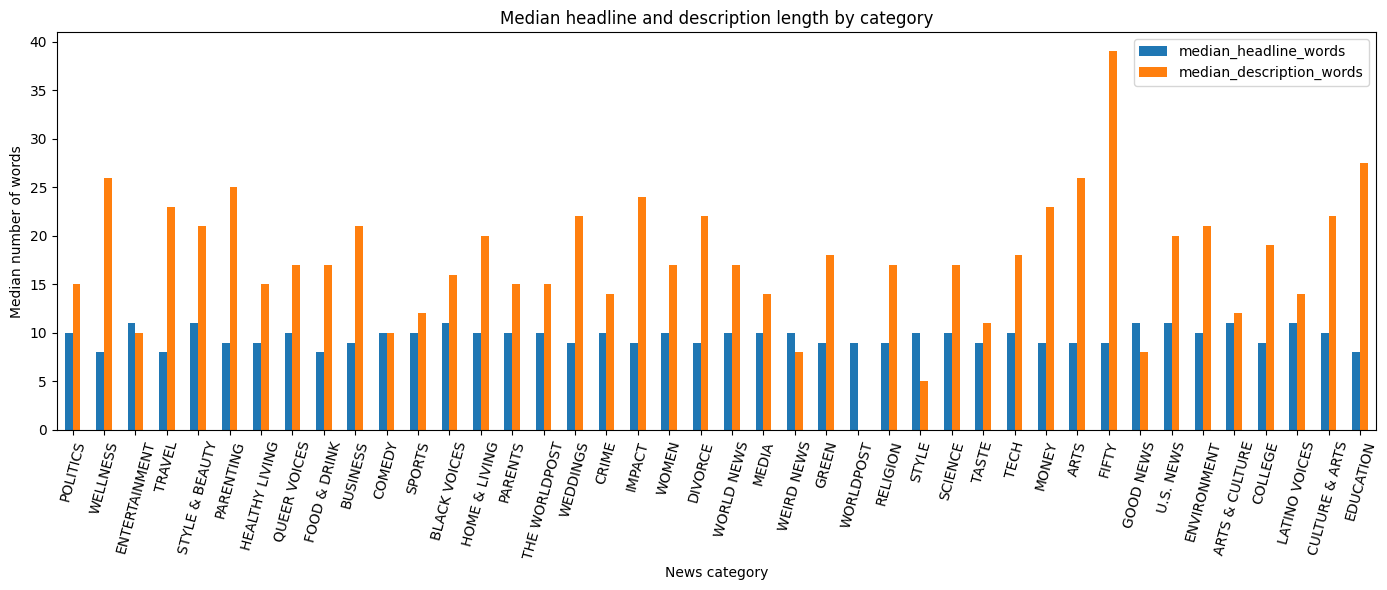

In [ ]:
category_text_stats[["median_headline_words", "median_description_words"]].plot(
    kind="bar", figsize=(14, 6)
)
plt.title("Median headline and description length by category")
plt.xlabel("News category")
plt.ylabel("Median number of words")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 4. Inspect class imbalance



In [ ]:
category_counts = df["category"].value_counts()
category_percentages = df["category"].value_counts(normalize=True).mul(100)

class_distribution = pd.DataFrame({
    "article_count": category_counts,
    "percentage": category_percentages
})

display(class_distribution.round(2))

print("Largest category:", category_counts.idxmax(),
      f"({category_counts.max():,} rows)")
print("Smallest category:", category_counts.idxmin(),
      f"({category_counts.min():,} rows)")
print("Largest/smallest category count ratio:",
      round(category_counts.max() / category_counts.min(), 2))

,article_count,percentage
category,,
POLITICS,35478,17.05
WELLNESS,17896,8.60
ENTERTAINMENT,17321,8.32
TRAVEL,9875,4.75
STYLE & BEAUTY,9330,4.48
PARENTING,8740,4.20
HEALTHY LIVING,6684,3.21
QUEER VOICES,6337,3.05
FOOD & DRINK,6335,3.04


Largest category: POLITICS (35,478 rows)
Smallest category: EDUCATION (1,014 rows)
Largest/smallest category count ratio: 34.99


## 5. URL cleaning confirmation


In [ ]:
url_pattern = r"https?://\S+|(?<!\w)www\.\S+"

headline_url_mask = df["lower_headlines"].fillna("").str.contains(
    url_pattern, regex=True, na=False
)
description_url_mask = df["lower_description"].fillna("").str.contains(
    url_pattern, regex=True, na=False
)

print("Headline rows with URL-like text:", int(headline_url_mask.sum()))
print("Description rows with URL-like text:", int(description_url_mask.sum()))

display(df.loc[headline_url_mask, [
    "headline", "headline_clean", "category"
]].head(15))

display(df.loc[description_url_mask, [
    "short_description", "description_clean", "category"
]].head(15))

Headline rows with URL-like text: 2
Description rows with URL-like text: 152


,headline,headline_clean,category
94420,Wendy Williams Announces 12-City ‘Sit Down Tour’ Read more at http://www.eurweb.com/2015/07/wendy-williWendy Williams Announces 12-City ‘Sit Down Tour’ Read more at http://www.eurweb.com/2015/07/wggendy-williams-announces-12-city-sit-down-tour/#CzdwTvg7bx2ZhiMt.99ams-announces-12-city-sit-down-tour/#CzdwTvg7bx2ZhiMt.99,wendy williams announces 12-city ‘sit down tour’ read more at williams announces 12-city ‘sit down tour’ read more at,BLACK VOICES
174199,Georgia Students Struggle On Test Tied To Common Core Math Course | Www.ajc.com,georgia students struggle on test tied to common core math course |,PARENTING


,short_description,description_clean,category
25330,1. Call your representatives. You can find who you’re representatives are at https://whoismyrepresentative.com/ If you want,1. call your representatives. you can find who you’re representatives are at if you want,POLITICS
31791,"5. Pack Less. My favorite travel writer, Rick Steves, https://www.ricksteves.com says there are travelers who pack light","5. pack less. my favorite travel writer, rick steves, says there are travelers who pack light",TRAVEL
43536,http://data.huffingtonpost.com/2017/medicaid-expansion,,POLITICS
56555,"Researchers from the Rollins School of Public Health at Emory University unveiled a new website, www.preplocator.org, that","researchers from the rollins school of public health at emory university unveiled a new website, that",QUEER VOICES
56812,http://elections.huffingtonpost.com/2016/forecast/senate,,POLITICS
106569,"Scott Blankenship, founder and CEO of www.amplifydpledges.com, a social activism startup based in Berkeley, California, is concerned about the health risks and antibiotic-laden milk.","scott blankenship, founder and ceo of a social activism startup based in berkeley, california, is concerned about the health risks and antibiotic-laden milk.",GREEN
107409,"When the Black and Missing Foundation, Inc (www.BAMFI.org) began in 2008, 30 percent of all persons missing were of color. Sadly, that number has grown -- seemingly to a new record setting incline.","when the black and missing foundation, inc ( began in 2008, 30 percent of all persons missing were of color. sadly, that number has grown -- seemingly to a new record setting incline.",BLACK VOICES
133899,LUNCH Phone: 813-248-4961 Online: www.saturdaymorningmarket.com There are other dim sum choices in Tampa - China Yuan and,lunch phone: 813-248-4961 online: there are other dim sum choices in tampa - china yuan and,TRAVEL
134357,Mentally ill people aren’t killers. Angry people are. Read more on www.slate.com,mentally ill people aren’t killers. angry people are. read more on,WELLNESS
135262,"LIKE MotherWoman on Facebook: https://www.facebook.com/MotherWoman When my daughter was one and a half, I had to be away","like motherwoman on facebook: when my daughter was one and a half, i had to be away",PARENTING


## 6. Check whether cleaning left awkward whitespace or empty text


In [ ]:
# Collapse repeated whitespace and trim the ends
df["headline_clean"] = df["headline_clean"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
df["description_clean"] = df["description_clean"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()

print("Empty cleaned headlines:", int(df["headline_clean"].eq("").sum()))
print("Empty cleaned descriptions:", int(df["description_clean"].eq("").sum()))

display(df[[
    "headline", "headline_clean",
    "short_description", "description_clean"
]].sample(min(10, len(df)), random_state=42))

Empty cleaned headlines: 0
Empty cleaned descriptions: 19605


,headline,headline_clean,short_description,description_clean
102449,Wrongfully Convicted Man Reflects On 30 Years Behind Bars,wrongfully convicted man reflects on 30 years behind bars,,
44471,Global Artists Come Together For Anti-Trump Track Celebrating Queer Love,global artists come together for anti-trump track celebrating queer love,"""You will not ignore us.""","""you will not ignore us."""
127048,"For Your Viewing Pleasure, We Present Some Nude Piles As Art (NSFW)","for your viewing pleasure, we present some nude piles as art (nsfw)",,
160916,"Vintage IKEA Ad Says Store Is The ""Only Sensible Way To Buy Furniture"" (PHOTO)","vintage ikea ad says store is the ""only sensible way to buy furniture"" (photo)",We respectfully disagree.,we respectfully disagree.
126008,WATCH: Robotic 'Pack Mule' Can Take On Any Terrain,watch: robotic 'pack mule' can take on any terrain,,
96778,Jeb Bush Among Conservatives Criticizing Pope For Climate Change,jeb bush among conservatives criticizing pope for climate change,,
109166,Baptist Minister In Hot Water Over Comments On Ten Commandments,baptist minister in hot water over comments on ten commandments,,
193811,Black Voices Atlanta Spotlight: 'Facts of Life' Actress Kim Fields Loves The Professional Opportunities in Atlanta,black voices atlanta spotlight: 'facts of life' actress kim fields loves the professional opportunities in atlanta,"As the former capitol of the ""Old South,"" Atlanta is also the same city that gave birth to the Civil Rights Movement. Today","as the former capitol of the ""old south,"" atlanta is also the same city that gave birth to the civil rights movement. today"
54241,Amazon Set To Launch Convenience Stores: Report,amazon set to launch convenience stores: report,The expansion comes less than a year after the online retailer opened a chain of brick-and-mortar bookstores.,the expansion comes less than a year after the online retailer opened a chain of brick-and-mortar bookstores.
123796,'TMNT' Sequel Is Already In The Works,'tmnt' sequel is already in the works,,


## 7. Final EDA report

In [ ]:
print("FINAL EDA SNAPSHOT")
print("-" * 40)
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Number of categories: {df['category'].nunique()}")
print(f"Duplicate full rows: {df.duplicated().sum():,}")
print(f"Missing headlines: {df['headline'].isna().sum():,}")
print(f"Empty/whitespace headlines: {df['headline'].fillna('').astype(str).str.strip().eq('').sum():,}")
print(f"Missing descriptions: {df['short_description'].isna().sum():,}")
print(f"Empty/whitespace descriptions: {df['short_description'].fillna('').astype(str).str.strip().eq('').sum():,}")
print(f"Median headline words: {df['headline_word_count'].median():.1f}")
print(f"Median description words: {df['description_word_count'].median():.1f}")
print(f"Most frequent category: {df['category'].value_counts().idxmax()}")
print(f"Least frequent category: {df['category'].value_counts().idxmin()}")

FINAL EDA SNAPSHOT
----------------------------------------
Rows: 208,102
Columns: 15
Number of categories: 42
Duplicate full rows: 0
Missing headlines: 0
Empty/whitespace headlines: 0
Missing descriptions: 0
Empty/whitespace descriptions: 19,603
Median headline words: 10.0
Median description words: 19.0
Most frequent category: POLITICS
Least frequent category: EDUCATION


## Machine Learning

## TF-IDF Feature Extraction



In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

required_columns = {"category", "headline_clean", "description_clean"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(
        f"The EDA dataframe is missing columns: {sorted(missing_columns)}. "
        "Run the EDA cleaning cells before this TF-IDF section."
    )


ml_df = df[["category", "headline_clean", "description_clean"]].copy()
ml_df["category"] = ml_df["category"].fillna("").astype(str).str.strip().str.upper()
ml_df["headline_clean"] = ml_df["headline_clean"].fillna("").astype(str).str.strip()
ml_df["description_clean"] = ml_df["description_clean"].fillna("").astype(str).str.strip()


ml_df = ml_df[
    ml_df["category"].ne("") & ml_df["headline_clean"].ne("")
].copy()


ml_df["combined_text"] = (
    ml_df["headline_clean"] + " " + ml_df["description_clean"]
).str.replace(r"\s+", " ", regex=True).str.strip()

X = ml_df["combined_text"]
y = ml_df["category"]

print(f"Rows used for TF-IDF: {len(ml_df):,}")
print(f"Number of categories: {y.nunique()}")
print("Most common categories:")
display(y.value_counts().head(10).rename("article_count").to_frame())


Rows used for TF-IDF: 208,102
Number of categories: 42
Most common categories:


,article_count
category,
POLITICS,35478
WELLNESS,17896
ENTERTAINMENT,17321
TRAVEL,9875
STYLE & BEAUTY,9330
PARENTING,8740
HEALTHY LIVING,6684
QUEER VOICES,6337
FOOD & DRINK,6335


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")


Training rows: 166,481
Testing rows:  41,621


In [ ]:

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    max_features=100_000,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF feature extraction completed successfully.")
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape: ", X_test_tfidf.shape)
print("Vocabulary size:      ", len(tfidf_vectorizer.vocabulary_))
print("Training non-zero values:", f"{X_train_tfidf.nnz:,}")
print("Testing non-zero values: ", f"{X_test_tfidf.nnz:,}")


feature_names = tfidf_vectorizer.get_feature_names_out()
print("Example TF-IDF terms:", feature_names[:30].tolist())


TF-IDF feature extraction completed successfully.
Training TF-IDF shape: (166481, 100000)
Testing TF-IDF shape:  (41621, 100000)
Vocabulary size:       100000
Training non-zero values: 3,095,268
Testing non-zero values:  750,845
Example TF-IDF terms: ['00', '000', '000 000', '000 20', '000 500', '000 acres', '000 american', '000 americans', '000 animals', '000 auction', '000 barrels', '000 calories', '000 car', '000 cases', '000 cash', '000 child', '000 children', '000 civilians', '000 day', '000 days', '000 deaths', '000 donation', '000 employees', '000 feet', '000 fine', '000 gallons', '000 gets', '000 help', '000 homes', '000 jobs']


##Multinomial Naive Bayes




In [ ]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report
)
import pandas as pd


required_vars = [
    "X_train_tfidf", "X_test_tfidf", "y_train", "y_test"
]
missing_vars = [name for name in required_vars if name not in globals()]
if missing_vars:
    raise NameError(
        f"Missing variables: {missing_vars}. Run the TF-IDF cells above first."
    )

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape: ", X_test_tfidf.shape)
print("Training labels:", len(y_train))
print("Testing labels: ", len(y_test))


nb_model = MultinomialNB(alpha=0.5)
nb_model.fit(X_train_tfidf, y_train)


nb_predictions = nb_model.predict(X_test_tfidf)


nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision, nb_recall, nb_macro_f1, _ = precision_recall_fscore_support(
    y_test, nb_predictions, average="macro", zero_division=0
)
nb_weighted_precision, nb_weighted_recall, nb_weighted_f1, _ = (
    precision_recall_fscore_support(
        y_test, nb_predictions, average="weighted", zero_division=0
    )
)

nb_results = pd.DataFrame([{
    "Model": "Multinomial Naive Bayes",
    "Accuracy": nb_accuracy,
    "Macro Precision": nb_precision,
    "Macro Recall": nb_recall,
    "Macro F1": nb_macro_f1,
    "Weighted F1": nb_weighted_f1
}])

print("\nMultinomial Naive Bayes results:")
display(nb_results.style.format({
    "Accuracy": "{:.4f}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}"
}))

print("\nDetailed classification report:")
print(classification_report(y_test, nb_predictions, zero_division=0))


nb_results.to_csv("naive_bayes_tfidf_results.csv", index=False)
print("Saved: naive_bayes_tfidf_results.csv")


Training TF-IDF shape: (166481, 100000)
Testing TF-IDF shape:  (41621, 100000)
Training labels: 166481
Testing labels:  41621

Multinomial Naive Bayes results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Multinomial Naive Bayes,0.4853,0.6040,0.1999,0.2119,0.3947



Detailed classification report:
                precision    recall  f1-score   support

          ARTS       0.00      0.00      0.00       302
ARTS & CULTURE       0.00      0.00      0.00       268
  BLACK VOICES       0.78      0.08      0.14       915
      BUSINESS       0.65      0.18      0.28      1196
       COLLEGE       0.00      0.00      0.00       229
        COMEDY       0.83      0.10      0.18      1069
         CRIME       0.63      0.21      0.32       711
CULTURE & ARTS       0.67      0.01      0.02       211
       DIVORCE       0.92      0.25      0.39       684
     EDUCATION       0.00      0.00      0.00       203
 ENTERTAINMENT       0.46      0.84      0.59      3464
   ENVIRONMENT       1.00      0.03      0.05       274
         FIFTY       0.00      0.00      0.00       280
  FOOD & DRINK       0.63      0.63      0.63      1267
     GOOD NEWS       0.67      0.01      0.01       280
         GREEN       0.52      0.02      0.04       523
HEALTHY LIVING

## Naive Bayes — Confusion Matrix and Misclassified Headlines

The confusion matrix shows correct and incorrect category predictions. The misclassification table helps inspect examples where the predicted category differs from the actual category.


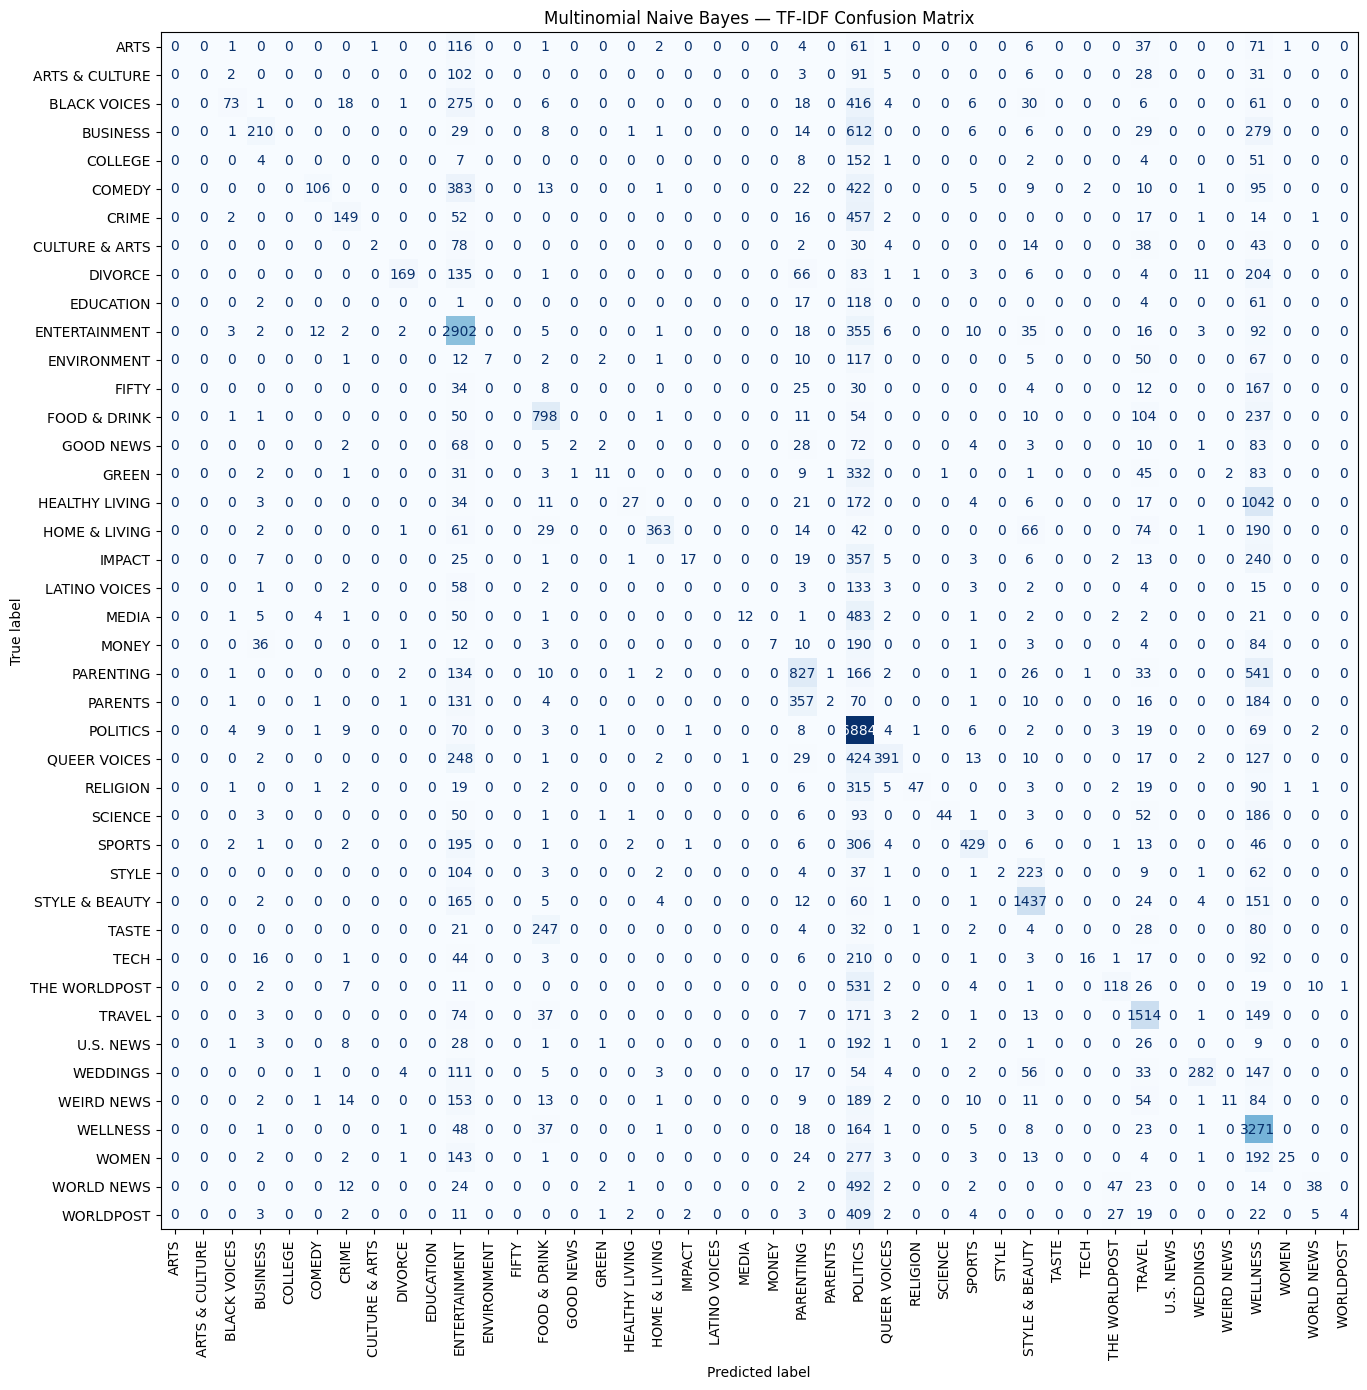

Incorrect predictions: 21,424 of 41,621 test rows


,text,actual_category,predicted_category
0,knight news challenge gives $3.2m to 22 ideas to inform the public and increase voting new projects aim to increase civic engagement in the face of historically low voter turnout,TECH,POLITICS
1,"cops write super-friendly letter to wanted woman ""you don't text, you don't call back and haven't accepted our friend request.""",CRIME,POLITICS
2,"why we won’t see trump-like nationalism in indonesia ""america first"" is based in exclusivism, but indonesia’s nationalism has far more pluralistic connotations.",THE WORLDPOST,POLITICS
3,research once again proves abortion restrictions punish poor women the most access is a class-based issue.,WOMEN,POLITICS
4,idina menzel says 'karma' is behind donald trump's rumored inauguration day problems the president-elect reportedly had a difficult time finding anyone to perform on his big day.,ENTERTAINMENT,POLITICS
5,5 tips for not screwing up valentine's day this year so many couples screw up the biggest romantic holiday of the year. and then they feel bitter about it. let's avoid that this year!,WEDDINGS,WELLNESS
6,politics as usual: how the federal government fails working parents change is hard and good policies aren't enough in a culture that doesn't prioritize caregiving. for a glimpse into the challenges of creating a truly family-friendly culture we only need to look to america's largest employer -- the federal government.,PARENTS,POLITICS
7,the 8 things that can cause dizziness,FIFTY,WELLNESS
8,"tiny hummingbird falls in love with the dog who saved her there was once a time when rex was living on the streets as a stray, but that all changed last year after he was rescued",GOOD NEWS,POLITICS
9,"kyle rittenhouse jury wraps up 3rd day of deliberations, no verdict yet rittenhouse is on trial for killing two men and wounding a third with a rifle during a turbulent night of protests that erupted in kenosha in the summer of 2020.",U.S. NEWS,CRIME


Saved: naive_bayes_misclassified_examples.csv (up to 1,000 examples)


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

category_labels = sorted(pd.Series(y_test).astype(str).unique())
fig, ax = plt.subplots(figsize=(17, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    labels=category_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Multinomial Naive Bayes — TF-IDF Confusion Matrix")
plt.tight_layout()
plt.show()


nb_errors = pd.DataFrame({
    "text": X_test.to_numpy(),
    "actual_category": pd.Series(y_test).to_numpy(),
    "predicted_category": nb_predictions
})
nb_errors = nb_errors[
    nb_errors["actual_category"] != nb_errors["predicted_category"]
].reset_index(drop=True)

print(f"Incorrect predictions: {len(nb_errors):,} of {len(y_test):,} test rows")
display(nb_errors.head(30))
nb_errors.head(1000).to_csv("naive_bayes_misclassified_examples.csv", index=False)
print("Saved: naive_bayes_misclassified_examples.csv (up to 1,000 examples)")


##  Logistic Regression



In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
import pandas as pd
import time


required_vars = [
    "X_train_tfidf", "X_test_tfidf", "y_train", "y_test"
]
missing_vars = [name for name in required_vars if name not in globals()]
if missing_vars:
    raise NameError(
        f"Missing variables: {missing_vars}. Run the TF-IDF cells first."
    )

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape: ", X_test_tfidf.shape)
print("Training labels:", len(y_train))
print("Testing labels: ", len(y_test))

logreg_model = LogisticRegression(
    C=4.0,
    solver="lbfgs",
    max_iter=200,
    class_weight=None,
    random_state=42
)

start_time = time.time()
print("Training Logistic Regression... this may take several minutes on the full dataset.")
logreg_model.fit(X_train_tfidf, y_train)
logreg_fit_seconds = time.time() - start_time

logreg_predictions = logreg_model.predict(X_test_tfidf)


logreg_accuracy = accuracy_score(y_test, logreg_predictions)
logreg_precision, logreg_recall, logreg_macro_f1, _ = (
    precision_recall_fscore_support(
        y_test, logreg_predictions, average="macro", zero_division=0
    )
)
logreg_weighted_precision, logreg_weighted_recall, logreg_weighted_f1, _ = (
    precision_recall_fscore_support(
        y_test, logreg_predictions, average="weighted", zero_division=0
    )
)

logreg_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": logreg_accuracy,
    "Macro Precision": logreg_precision,
    "Macro Recall": logreg_recall,
    "Macro F1": logreg_macro_f1,
    "Weighted F1": logreg_weighted_f1,
    "Fit time (seconds)": round(logreg_fit_seconds, 2),
    "Iterations used": int(logreg_model.n_iter_[0])
}])

print("\nLogistic Regression results:")
display(logreg_results.style.format({
    "Accuracy": "{:.4f}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}",
    "Fit time (seconds)": "{:.2f}"
}))

print("\nDetailed classification report:")
print(classification_report(y_test, logreg_predictions, zero_division=0))

logreg_results.to_csv("logistic_regression_tfidf_results.csv", index=False)
print("Saved: logistic_regression_tfidf_results.csv")


Training TF-IDF shape: (166481, 100000)
Testing TF-IDF shape:  (41621, 100000)
Training labels: 166481
Testing labels:  41621
Training Logistic Regression... this may take several minutes on the full dataset.


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Logistic Regression results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Fit time (seconds),Iterations used
0,Logistic Regression,0.6219,0.5571,0.4571,0.4891,0.6046,390.08,200



Detailed classification report:
                precision    recall  f1-score   support

          ARTS       0.37      0.22      0.28       302
ARTS & CULTURE       0.41      0.22      0.28       268
  BLACK VOICES       0.56      0.45      0.50       915
      BUSINESS       0.53      0.53      0.53      1196
       COLLEGE       0.49      0.40      0.44       229
        COMEDY       0.58      0.46      0.51      1069
         CRIME       0.55      0.55      0.55       711
CULTURE & ARTS       0.66      0.26      0.37       211
       DIVORCE       0.83      0.73      0.78       684
     EDUCATION       0.53      0.35      0.42       203
 ENTERTAINMENT       0.64      0.77      0.70      3464
   ENVIRONMENT       0.48      0.24      0.32       274
         FIFTY       0.53      0.19      0.28       280
  FOOD & DRINK       0.63      0.75      0.68      1267
     GOOD NEWS       0.47      0.23      0.30       280
         GREEN       0.42      0.37      0.40       523
HEALTHY LIVING

## Logistic Regression — Confusion Matrix and Misclassified Headlines




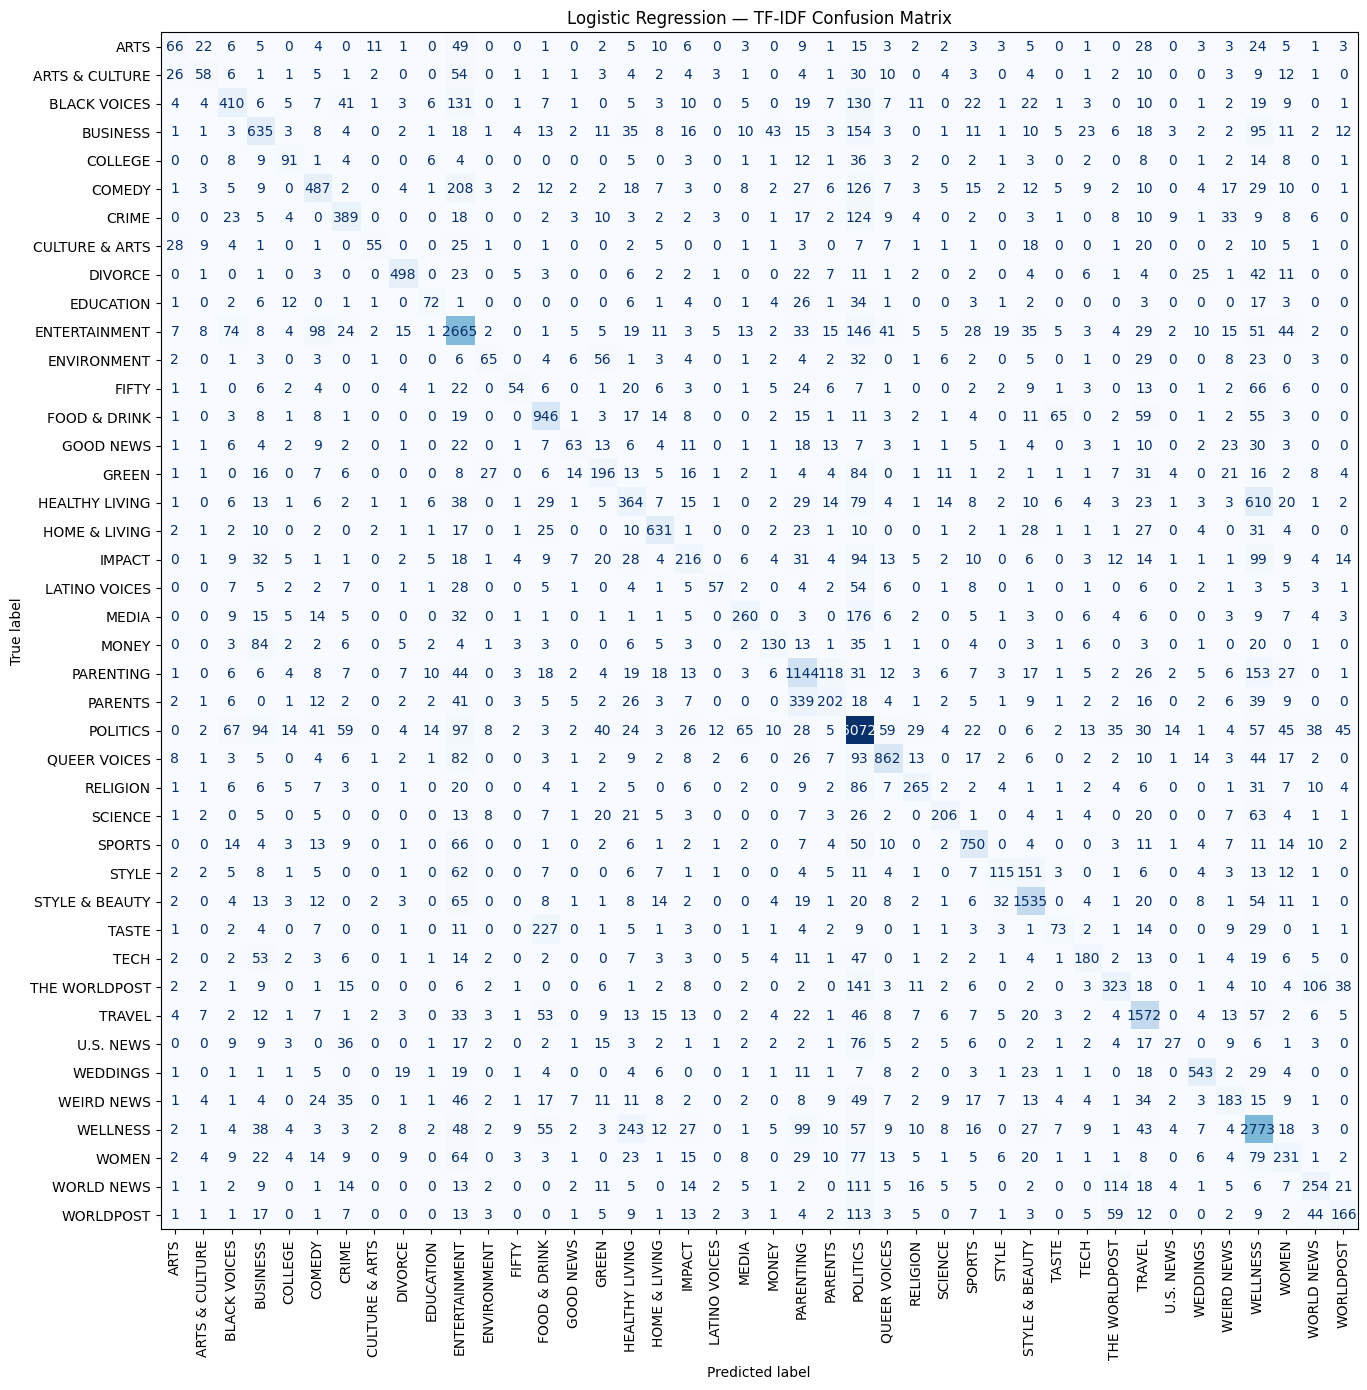

Incorrect predictions: 15,737 of 41,621 test rows


,text,actual_category,predicted_category
0,knight news challenge gives $3.2m to 22 ideas to inform the public and increase voting new projects aim to increase civic engagement in the face of historically low voter turnout,TECH,POLITICS
1,"cops write super-friendly letter to wanted woman ""you don't text, you don't call back and haven't accepted our friend request.""",CRIME,BLACK VOICES
2,"why we won’t see trump-like nationalism in indonesia ""america first"" is based in exclusivism, but indonesia’s nationalism has far more pluralistic connotations.",THE WORLDPOST,POLITICS
3,officer charged with murder in shooting death of justine damond minneapolis police officer mohamed noor killed damond in july after she called 911.,CRIME,POLITICS
4,politics as usual: how the federal government fails working parents change is hard and good policies aren't enough in a culture that doesn't prioritize caregiving. for a glimpse into the challenges of creating a truly family-friendly culture we only need to look to america's largest employer -- the federal government.,PARENTS,POLITICS
5,the 8 things that can cause dizziness,FIFTY,WELLNESS
6,"tiny hummingbird falls in love with the dog who saved her there was once a time when rex was living on the streets as a stray, but that all changed last year after he was rescued",GOOD NEWS,GREEN
7,"online therapy necessary to address growing mental health burden as of now, the global mental health system is only serving around 10 percent of patients.",HEALTHY LIVING,WELLNESS
8,"man jailed for swearing during 911 call: the sad saga of boyd green and a senseless arrest although green v. chitwood seems at first glance trivial, it is both the backstory and the vague terms used in statute that make green's arrest so outrageous and egregious.",CRIME,POLITICS
9,"as global policy moves to expand digital rights, u.s faces crucial fight over equal access to the internet by: karin deutsch karlekar and christopher hamlin in 2013, inventor of the internet tim berners lee reflected, “when you",POLITICS,TECH


Saved: logistic_regression_misclassified_examples.csv (up to 1,000 examples)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

category_labels = sorted(pd.Series(y_test).astype(str).unique())
fig, ax = plt.subplots(figsize=(17, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logreg_predictions,
    labels=category_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Logistic Regression — TF-IDF Confusion Matrix")
plt.tight_layout()
plt.show()

logreg_errors = pd.DataFrame({
    "text": X_test.to_numpy(),
    "actual_category": pd.Series(y_test).to_numpy(),
    "predicted_category": logreg_predictions
})
logreg_errors = logreg_errors[
    logreg_errors["actual_category"] != logreg_errors["predicted_category"]
].reset_index(drop=True)

print(f"Incorrect predictions: {len(logreg_errors):,} of {len(y_test):,} test rows")
display(logreg_errors.head(30))
logreg_errors.head(1000).to_csv(
    "logistic_regression_misclassified_examples.csv", index=False
)
print("Saved: logistic_regression_misclassified_examples.csv (up to 1,000 examples)")


## Compared Naive Bayes, Logistic Regression and Linear SVM




In [ ]:
comparison_rows = []
for result_name in ["nb_results", "logreg_results", "svm_results"]:
    if result_name in globals():
        result_df = globals()[result_name]
        if isinstance(result_df, pd.DataFrame) and not result_df.empty:
            comparison_rows.append(result_df.iloc[0].to_dict())

model_comparison = pd.DataFrame(comparison_rows)
if model_comparison.empty:
    raise RuntimeError("No model results found. Run the Naive Bayes, Logistic Regression, and Linear SVM cells first.")

print("Model comparison:")
display(model_comparison.style.format({
    "Accuracy": "{:.4f}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}"
}))
model_comparison.to_csv("naive_bayes_logistic_regression_linear_svm_comparison.csv", index=False)
print("Saved: naive_bayes_logistic_regression_linear_svm_comparison.csv")


Model comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Fit time (seconds),Iterations used
0,Multinomial Naive Bayes,0.4853,0.6040,0.1999,0.2119,0.3947,nan,nan
1,Logistic Regression,0.6219,0.5571,0.4571,0.4891,0.6046,390.080000,200.000000


Saved: naive_bayes_logistic_regression_linear_svm_comparison.csv


## Train Linear SVM



In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
import pandas as pd
import time
import warnings
from sklearn.exceptions import ConvergenceWarning

required_vars = ["X_train_tfidf", "X_test_tfidf", "y_train", "y_test"]
missing_vars = [name for name in required_vars if name not in globals()]
if missing_vars:
    raise NameError(f"Missing variables: {missing_vars}. Run the TF-IDF cells first.")

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape: ", X_test_tfidf.shape)
print("Training labels:", len(y_train))
print("Testing labels: ", len(y_test))


use_dual = X_train_tfidf.shape[0] <= X_train_tfidf.shape[1]
svm_model = LinearSVC(
    C=1.0,
    class_weight=None,
    max_iter=5000,
    dual=use_dual,
    random_state=42
)

start_time = time.time()
print("Training Linear SVM... this may take several minutes on the full dataset.", flush=True)
with warnings.catch_warnings(record=True) as svm_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    svm_model.fit(X_train_tfidf, y_train)
svm_fit_seconds = time.time() - start_time


svm_predictions = svm_model.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision, svm_recall, svm_macro_f1, _ = precision_recall_fscore_support(
    y_test, svm_predictions, average="macro", zero_division=0
)
_, _, svm_weighted_f1, _ = precision_recall_fscore_support(
    y_test, svm_predictions, average="weighted", zero_division=0
)

svm_results = pd.DataFrame([{
    "Model": "Linear SVM",
    "Accuracy": svm_accuracy,
    "Macro Precision": svm_precision,
    "Macro Recall": svm_recall,
    "Macro F1": svm_macro_f1,
    "Weighted F1": svm_weighted_f1,
    "Fit time (seconds)": round(svm_fit_seconds, 2),
    "Iterations used (max across classes)": int(np.max(np.asarray(svm_model.n_iter_)))
}])

print("\nLinear SVM results:")
display(svm_results.style.format({
    "Accuracy": "{:.4f}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}",
    "Fit time (seconds)": "{:.2f}"
}))

if svm_warnings:
    print("\nWarning: Linear SVM produced a convergence warning. Consider increasing max_iter to 10000.")
    for warning_item in svm_warnings[:3]:
        print(str(warning_item.message))

print("\nDetailed classification report:")
print(classification_report(y_test, svm_predictions, zero_division=0))
svm_results.to_csv("linear_svm_tfidf_results.csv", index=False)
print("Saved: linear_svm_tfidf_results.csv")


Training TF-IDF shape: (166481, 100000)
Testing TF-IDF shape:  (41621, 100000)
Training labels: 166481
Testing labels:  41621
Training Linear SVM... this may take several minutes on the full dataset.

Linear SVM results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Fit time (seconds),Iterations used (max across classes)
0,Linear SVM,0.6156,0.5277,0.4601,0.4832,0.5998,134.57,25



Detailed classification report:
                precision    recall  f1-score   support

          ARTS       0.34      0.23      0.28       302
ARTS & CULTURE       0.39      0.21      0.27       268
  BLACK VOICES       0.52      0.45      0.48       915
      BUSINESS       0.51      0.49      0.50      1196
       COLLEGE       0.48      0.40      0.44       229
        COMEDY       0.55      0.47      0.51      1069
         CRIME       0.53      0.54      0.54       711
CULTURE & ARTS       0.59      0.30      0.40       211
       DIVORCE       0.78      0.75      0.77       684
     EDUCATION       0.48      0.35      0.41       203
 ENTERTAINMENT       0.65      0.74      0.69      3464
   ENVIRONMENT       0.42      0.23      0.30       274
         FIFTY       0.45      0.23      0.31       280
  FOOD & DRINK       0.62      0.73      0.67      1267
     GOOD NEWS       0.45      0.26      0.33       280
         GREEN       0.40      0.38      0.39       523
HEALTHY LIVING

## Linear SVM — Confusion Matrix and Misclassified Headlines

This visualizes the Linear SVM's correct and incorrect predictions and exports up to 1,000 misclassified test examples.


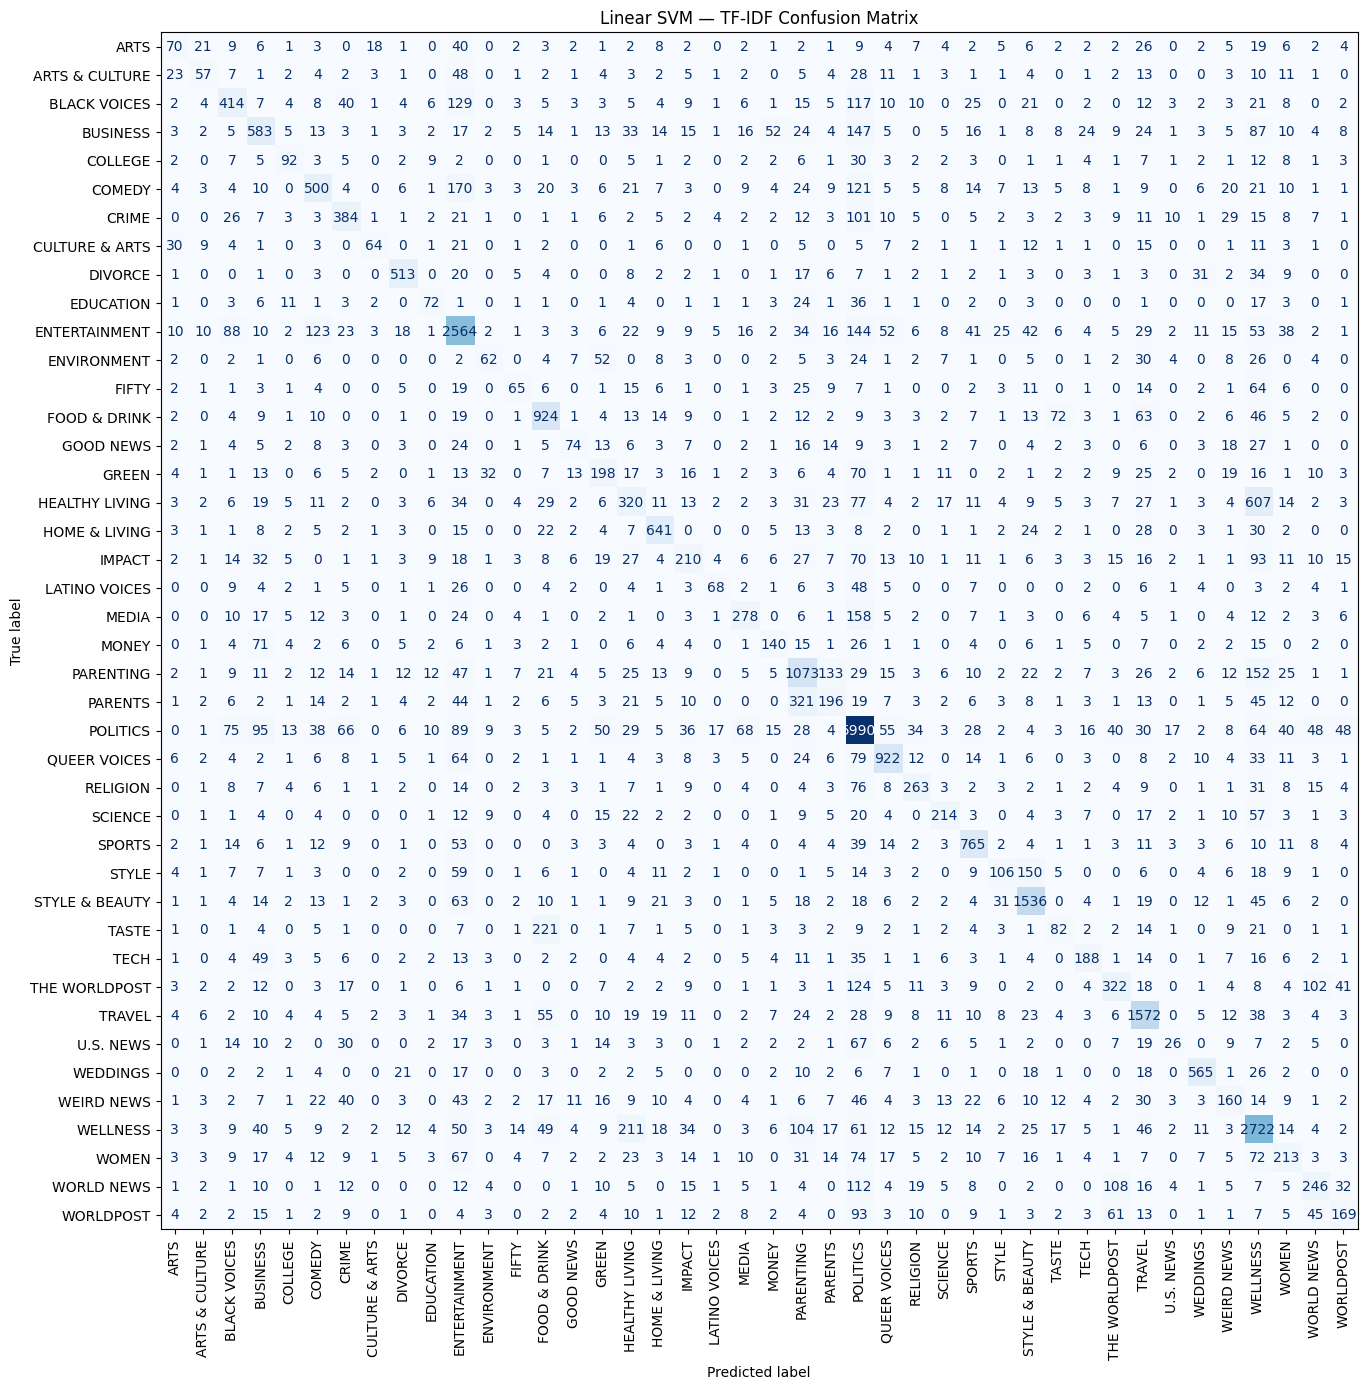

Incorrect predictions: 15,998 of 41,621 test rows


,text,actual_category,predicted_category
0,knight news challenge gives $3.2m to 22 ideas to inform the public and increase voting new projects aim to increase civic engagement in the face of historically low voter turnout,TECH,POLITICS
1,"why we won’t see trump-like nationalism in indonesia ""america first"" is based in exclusivism, but indonesia’s nationalism has far more pluralistic connotations.",THE WORLDPOST,POLITICS
2,5 tips for not screwing up valentine's day this year so many couples screw up the biggest romantic holiday of the year. and then they feel bitter about it. let's avoid that this year!,WEDDINGS,DIVORCE
3,officer charged with murder in shooting death of justine damond minneapolis police officer mohamed noor killed damond in july after she called 911.,CRIME,POLITICS
4,politics as usual: how the federal government fails working parents change is hard and good policies aren't enough in a culture that doesn't prioritize caregiving. for a glimpse into the challenges of creating a truly family-friendly culture we only need to look to america's largest employer -- the federal government.,PARENTS,POLITICS
5,"tiny hummingbird falls in love with the dog who saved her there was once a time when rex was living on the streets as a stray, but that all changed last year after he was rescued",GOOD NEWS,GREEN
6,"online therapy necessary to address growing mental health burden as of now, the global mental health system is only serving around 10 percent of patients.",HEALTHY LIVING,WELLNESS
7,"man jailed for swearing during 911 call: the sad saga of boyd green and a senseless arrest although green v. chitwood seems at first glance trivial, it is both the backstory and the vague terms used in statute that make green's arrest so outrageous and egregious.",CRIME,POLITICS
8,"as global policy moves to expand digital rights, u.s faces crucial fight over equal access to the internet by: karin deutsch karlekar and christopher hamlin in 2013, inventor of the internet tim berners lee reflected, “when you",POLITICS,TECH
9,looking at donald trump's innards is the scariest thing you'll do this halloween and you didn't think he could reveal anything else.,COMEDY,POLITICS


Saved: linear_svm_misclassified_examples.csv (up to 1,000 examples)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

category_labels = sorted(pd.Series(y_test).astype(str).unique())
fig, ax = plt.subplots(figsize=(17, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_predictions,
    labels=category_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Linear SVM — TF-IDF Confusion Matrix")
plt.tight_layout()
plt.show()

svm_errors = pd.DataFrame({
    "text": X_test.to_numpy(),
    "actual_category": pd.Series(y_test).to_numpy(),
    "predicted_category": svm_predictions
})
svm_errors = svm_errors[
    svm_errors["actual_category"] != svm_errors["predicted_category"]
].reset_index(drop=True)
print(f"Incorrect predictions: {len(svm_errors):,} of {len(y_test):,} test rows")
display(svm_errors.head(30))
svm_errors.head(1000).to_csv("linear_svm_misclassified_examples.csv", index=False)
print("Saved: linear_svm_misclassified_examples.csv (up to 1,000 examples)")


# Minimum Deliverables — Final Evaluation, Error Analysis, and Responsible AI



In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

required_vars = [
    "X_train_tfidf", "X_test_tfidf", "y_train", "y_test",
    "tfidf_vectorizer", "nb_predictions", "logreg_predictions",
    "svm_predictions", "nb_results", "logreg_results", "svm_results"
]
missing_vars = [name for name in required_vars if name not in globals()]
if missing_vars:
    raise NameError(
        f"Missing required outputs: {missing_vars}. "
        "Run TF-IDF, Naive Bayes, Logistic Regression, and Linear SVM cells first."
    )

feature_names = tfidf_vectorizer.get_feature_names_out()
y_train_values = pd.Series(y_train).reset_index(drop=True).astype(str).to_numpy()

top_terms_rows = []
for category in sorted(pd.Series(y_train_values).unique()):
    row_positions = np.flatnonzero(y_train_values == category)

    mean_scores = np.asarray(
        X_train_tfidf[row_positions].mean(axis=0)
    ).ravel()
    top_indices = mean_scores.argsort()[-10:][::-1]
    for rank, idx in enumerate(top_indices, start=1):
        if mean_scores[idx] > 0:
            top_terms_rows.append({
                "category": category,
                "rank": rank,
                "term": feature_names[idx],
                "mean_tfidf": float(mean_scores[idx]),
                "training_examples_in_category": int(len(row_positions))
            })

top_terms_by_category = pd.DataFrame(top_terms_rows)
print("Top TF-IDF terms by category (based on training data):")
display(top_terms_by_category.head(50))
top_terms_by_category.to_csv("top_tfidf_terms_by_category.csv", index=False)
print("Saved: top_tfidf_terms_by_category.csv")


Top TF-IDF terms by category (based on training data):


,category,rank,term,mean_tfidf,training_examples_in_category
0,ARTS,1,art,0.037717,1207
1,ARTS,2,artist,0.018378,1207
2,ARTS,3,artists,0.011344,1207
3,ARTS,4,new,0.010364,1207
4,ARTS,5,world,0.010212,1207
5,ARTS,6,opera,0.008323,1207
6,ARTS,7,theater,0.007608,1207
7,ARTS,8,music,0.007377,1207
8,ARTS,9,theatre,0.006876,1207
9,ARTS,10,photographer,0.006335,1207


Saved: top_tfidf_terms_by_category.csv


In [ ]:

comparison_rows = []
prediction_map = {
    "Multinomial Naive Bayes": nb_predictions,
    "Logistic Regression": logreg_predictions,
    "Linear SVM": svm_predictions
}
result_map = {
    "Multinomial Naive Bayes": nb_results,
    "Logistic Regression": logreg_results,
    "Linear SVM": svm_results
}

for model_name, prediction in prediction_map.items():
    result_frame = result_map[model_name]
    if not isinstance(result_frame, pd.DataFrame) or result_frame.empty:
        raise ValueError(f"Results for {model_name} are unavailable.")
    metric_row = result_frame.iloc[0].to_dict()
    comparison_rows.append(metric_row)

final_model_comparison = pd.DataFrame(comparison_rows)
sort_columns = [c for c in ["Macro F1", "Accuracy"] if c in final_model_comparison.columns]
final_model_comparison = final_model_comparison.sort_values(
    sort_columns, ascending=False
).reset_index(drop=True)

print("Final model comparison:")
display(final_model_comparison.style.format({
    c: "{:.4f}" for c in [
        "Accuracy", "Macro Precision", "Macro Recall",
        "Macro F1", "Weighted F1"
    ] if c in final_model_comparison.columns
}))
final_model_comparison.to_csv("final_model_comparison.csv", index=False)
print("Saved: final_model_comparison.csv")


best_model_name = final_model_comparison.iloc[0]["Model"]
best_prediction = prediction_map[best_model_name]
print(f"Selected for detailed error analysis: {best_model_name}")


Final model comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Fit time (seconds),Iterations used,Iterations used (max across classes)
0,Logistic Regression,0.6219,0.5571,0.4571,0.4891,0.6046,390.080000,200.000000,nan
1,Linear SVM,0.6156,0.5277,0.4601,0.4832,0.5998,134.570000,nan,25.000000
2,Multinomial Naive Bayes,0.4853,0.6040,0.1999,0.2119,0.3947,nan,nan,nan


Saved: final_model_comparison.csv
Selected for detailed error analysis: Logistic Regression


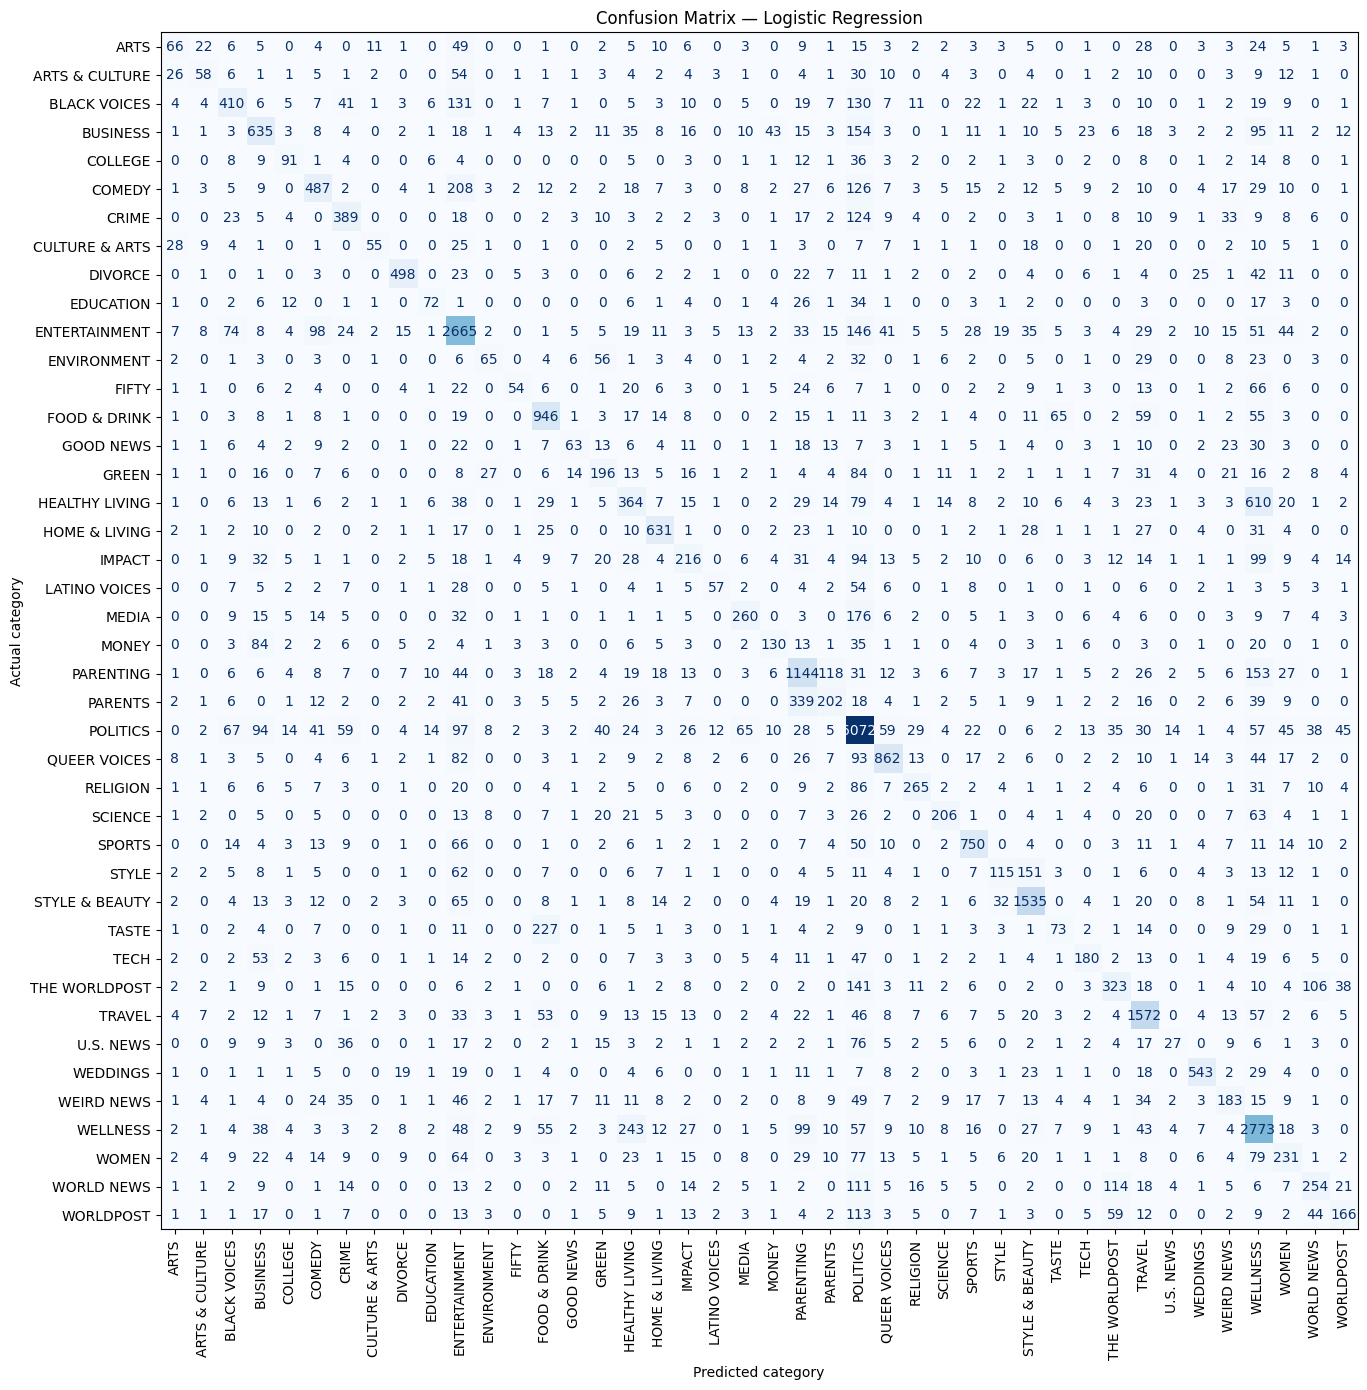

,Predicted: ARTS,Predicted: ARTS & CULTURE,Predicted: BLACK VOICES,Predicted: BUSINESS,Predicted: COLLEGE,Predicted: COMEDY,Predicted: CRIME,Predicted: CULTURE & ARTS,Predicted: DIVORCE,Predicted: EDUCATION,...,Predicted: TECH,Predicted: THE WORLDPOST,Predicted: TRAVEL,Predicted: U.S. NEWS,Predicted: WEDDINGS,Predicted: WEIRD NEWS,Predicted: WELLNESS,Predicted: WOMEN,Predicted: WORLD NEWS,Predicted: WORLDPOST
Actual: ARTS,66,22,6,5,0,4,0,11,1,0,...,1,0,28,0,3,3,24,5,1,3
Actual: ARTS & CULTURE,26,58,6,1,1,5,1,2,0,0,...,1,2,10,0,0,3,9,12,1,0
Actual: BLACK VOICES,4,4,410,6,5,7,41,1,3,6,...,3,0,10,0,1,2,19,9,0,1
Actual: BUSINESS,1,1,3,635,3,8,4,0,2,1,...,23,6,18,3,2,2,95,11,2,12
Actual: COLLEGE,0,0,8,9,91,1,4,0,0,6,...,2,0,8,0,1,2,14,8,0,1
Actual: COMEDY,1,3,5,9,0,487,2,0,4,1,...,9,2,10,0,4,17,29,10,0,1
Actual: CRIME,0,0,23,5,4,0,389,0,0,0,...,0,8,10,9,1,33,9,8,6,0
Actual: CULTURE & ARTS,28,9,4,1,0,1,0,55,0,0,...,0,1,20,0,0,2,10,5,1,0
Actual: DIVORCE,0,1,0,1,0,3,0,0,498,0,...,6,1,4,0,25,1,42,11,0,0
Actual: EDUCATION,1,0,2,6,12,0,1,1,0,72,...,0,0,3,0,0,0,17,3,0,0


Saved: best_model_confusion_matrix.csv


In [ ]:

category_labels = sorted(pd.Series(y_test).astype(str).unique())

fig, ax = plt.subplots(figsize=(17, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_prediction,
    labels=category_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title(f"Confusion Matrix — {best_model_name}")
ax.set_xlabel("Predicted category")
ax.set_ylabel("Actual category")
plt.tight_layout()
plt.show()


from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, best_prediction, labels=category_labels)
confusion_matrix_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in category_labels],
    columns=[f"Predicted: {label}" for label in category_labels]
)
display(confusion_matrix_df)
confusion_matrix_df.to_csv("best_model_confusion_matrix.csv", index=True)
print("Saved: best_model_confusion_matrix.csv")


In [ ]:

test_indices = X_test.index
error_examples = pd.DataFrame({
    "headline": ml_df.loc[test_indices, "headline_clean"].to_numpy(),
    "description": ml_df.loc[test_indices, "description_clean"].to_numpy(),
    "actual_category": pd.Series(y_test).astype(str).to_numpy(),
    "predicted_category": pd.Series(best_prediction).astype(str).to_numpy()
})
error_examples = error_examples[
    error_examples["actual_category"] != error_examples["predicted_category"]
].reset_index(drop=True)

print(
    f"{len(error_examples):,} of {len(y_test):,} test examples were misclassified "
    f"by {best_model_name}."
)
display(error_examples.head(30))
error_examples.to_csv("best_model_misclassified_headlines.csv", index=False)
print("Saved: best_model_misclassified_headlines.csv")


for model_name, prediction in prediction_map.items():
    model_errors = pd.DataFrame({
        "headline": ml_df.loc[test_indices, "headline_clean"].to_numpy(),
        "description": ml_df.loc[test_indices, "description_clean"].to_numpy(),
        "actual_category": pd.Series(y_test).astype(str).to_numpy(),
        "predicted_category": pd.Series(prediction).astype(str).to_numpy()
    })
    model_errors = model_errors[
        model_errors["actual_category"] != model_errors["predicted_category"]
    ].reset_index(drop=True)
    filename = (
        model_name.lower().replace(" ", "_").replace("-", "_")
        + "_misclassified_headlines.csv"
    )
    model_errors.head(1000).to_csv(filename, index=False)
    print(f"Saved up to 1,000 errors for {model_name}: {filename}")


15,737 of 41,621 test examples were misclassified by Logistic Regression.


,headline,description,actual_category,predicted_category
0,knight news challenge gives $3.2m to 22 ideas to inform the public and increase voting,new projects aim to increase civic engagement in the face of historically low voter turnout,TECH,POLITICS
1,cops write super-friendly letter to wanted woman,"""you don't text, you don't call back and haven't accepted our friend request.""",CRIME,BLACK VOICES
2,why we won’t see trump-like nationalism in indonesia,"""america first"" is based in exclusivism, but indonesia’s nationalism has far more pluralistic connotations.",THE WORLDPOST,POLITICS
3,officer charged with murder in shooting death of justine damond,minneapolis police officer mohamed noor killed damond in july after she called 911.,CRIME,POLITICS
4,politics as usual: how the federal government fails working parents,change is hard and good policies aren't enough in a culture that doesn't prioritize caregiving. for a glimpse into the challenges of creating a truly family-friendly culture we only need to look to america's largest employer -- the federal government.,PARENTS,POLITICS
5,the 8 things that can cause dizziness,,FIFTY,WELLNESS
6,tiny hummingbird falls in love with the dog who saved her,"there was once a time when rex was living on the streets as a stray, but that all changed last year after he was rescued",GOOD NEWS,GREEN
7,online therapy necessary to address growing mental health burden,"as of now, the global mental health system is only serving around 10 percent of patients.",HEALTHY LIVING,WELLNESS
8,man jailed for swearing during 911 call: the sad saga of boyd green and a senseless arrest,"although green v. chitwood seems at first glance trivial, it is both the backstory and the vague terms used in statute that make green's arrest so outrageous and egregious.",CRIME,POLITICS
9,"as global policy moves to expand digital rights, u.s faces crucial fight over equal access to the internet","by: karin deutsch karlekar and christopher hamlin in 2013, inventor of the internet tim berners lee reflected, “when you",POLITICS,TECH


Saved: best_model_misclassified_headlines.csv
Saved up to 1,000 errors for Multinomial Naive Bayes: multinomial_naive_bayes_misclassified_headlines.csv
Saved up to 1,000 errors for Logistic Regression: logistic_regression_misclassified_headlines.csv
Saved up to 1,000 errors for Linear SVM: linear_svm_misclassified_headlines.csv


# Evaluation and Extension — Required Project Metrics

**accuracy, macro precision, macro recall, macro F1, and weighted F1** from the three models' predictions on the same held-out test set.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

def calculate_classification_metrics(y_true, y_pred):
    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0
        )
    )
    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true, y_pred, average="weighted", zero_division=0
        )
    )
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_precision,
        "Weighted Recall": weighted_recall,
        "Weighted F1": weighted_f1
    }

prediction_map = {
    "Multinomial Naive Bayes": nb_predictions,
    "Logistic Regression": logreg_predictions,
    "Linear SVM": svm_predictions
}

metric_rows = []
for model_name, predictions in prediction_map.items():
    metric_rows.append({
        "Model": model_name,
        **calculate_classification_metrics(y_test, predictions)
    })

evaluation_metrics = pd.DataFrame(metric_rows).sort_values(
    ["Macro F1", "Accuracy"], ascending=False
).reset_index(drop=True)

print("Evaluation metrics on the same held-out test set:")
display(evaluation_metrics.style.format({
    column: "{:.4f}" for column in evaluation_metrics.columns
    if column != "Model"
}))
evaluation_metrics.to_csv("evaluation_metrics_all_models.csv", index=False)
print("Saved: evaluation_metrics_all_models.csv")




Evaluation metrics on the same held-out test set:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,0.6219,0.5571,0.4571,0.4891,0.6066,0.6219,0.6046
1,Linear SVM,0.6156,0.5277,0.4601,0.4832,0.5963,0.6156,0.5998
2,Multinomial Naive Bayes,0.4853,0.6040,0.1999,0.2119,0.5947,0.4853,0.3947


Saved: evaluation_metrics_all_models.csv


In [ ]:

category_counts = y.value_counts().rename_axis("category").reset_index(name="article_count")
category_counts["share_percent"] = (
    category_counts["article_count"] / category_counts["article_count"].sum() * 100
)
display(category_counts.head(15))
category_counts.to_csv("category_distribution_for_evaluation.csv", index=False)

majority_category = y_train.value_counts().idxmax()
majority_baseline_predictions = np.repeat(majority_category, len(y_test))
baseline_metrics = calculate_classification_metrics(
    y_test, majority_baseline_predictions
)
baseline_results = pd.DataFrame([{
    "Model": f"Majority baseline ({majority_category})",
    **baseline_metrics
}])

print("Majority-class baseline (predicts the most common training category every time):")
display(baseline_results.style.format({
    column: "{:.4f}" for column in baseline_results.columns
    if column != "Model"
}))

print("Majority category:", majority_category)
print("Largest category share: {:.2f}%".format(category_counts.iloc[0]["share_percent"]))
print("Compare model scores with this baseline; accuracy alone can be misleading on imbalanced data.")
baseline_results.to_csv("majority_class_baseline.csv", index=False)


,category,article_count,share_percent
0,POLITICS,35478,17.048371
1,WELLNESS,17896,8.599629
2,ENTERTAINMENT,17321,8.323322
3,TRAVEL,9875,4.745269
4,STYLE & BEAUTY,9330,4.483378
5,PARENTING,8740,4.199864
6,HEALTHY LIVING,6684,3.211886
7,QUEER VOICES,6337,3.045141
8,FOOD & DRINK,6335,3.044180
9,BUSINESS,5979,2.873110


Majority-class baseline (predicts the most common training category every time):


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,Majority baseline (POLITICS),0.1705,0.0041,0.0238,0.0069,0.0291,0.1705,0.0497


Majority category: POLITICS
Largest category share: 17.05%
Compare model scores with this baseline; accuracy alone can be misleading on imbalanced data.


## Compared headline-only versus headline + description




In [ ]:

required_columns = {"headline_clean", "description_clean"}
missing_columns = required_columns - set(ml_df.columns)
if missing_columns:
    raise ValueError(f"Missing cleaned text columns in ml_df: {sorted(missing_columns)}")


X_headline_train = ml_df.loc[X_train.index, "headline_clean"].fillna("").astype(str)
X_headline_test = ml_df.loc[X_test.index, "headline_clean"].fillna("").astype(str)

X_combined_train = (
    ml_df.loc[X_train.index, "headline_clean"].fillna("").astype(str)
    + " "
    + ml_df.loc[X_train.index, "description_clean"].fillna("").astype(str)
).str.replace(r"\s+", " ", regex=True).str.strip()

X_combined_test = (
    ml_df.loc[X_test.index, "headline_clean"].fillna("").astype(str)
    + " "
    + ml_df.loc[X_test.index, "description_clean"].fillna("").astype(str)
).str.replace(r"\s+", " ", regex=True).str.strip()

print("Headline-only train/test rows:", len(X_headline_train), "/", len(X_headline_test))
print("Combined-text train/test rows:", len(X_combined_train), "/", len(X_combined_test))
print("Labels aligned:", len(y_train) == len(X_headline_train),
      "and", len(y_test) == len(X_headline_test))


Headline-only train/test rows: 166481 / 41621
Combined-text train/test rows: 166481 / 41621
Labels aligned: True and True


In [ ]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
import time

def make_extension_vectorizer():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        max_features=100_000,
        sublinear_tf=True,
        dtype=np.float32
    )

def make_extension_model(model_name, n_samples, n_features):
    if model_name == "Multinomial Naive Bayes":
        return MultinomialNB(alpha=0.5)
    if model_name == "Logistic Regression":
        return LogisticRegression(
            C=4.0, solver="lbfgs", max_iter=200,
            class_weight=None, random_state=42
        )
    if model_name == "Linear SVM":

        return LinearSVC(
            C=1.0, class_weight=None, max_iter=5000,
            dual=(n_samples <= n_features), random_state=42
        )
    raise ValueError(f"Unknown model: {model_name}")

extension_rows = []
extension_fitted_models = {}

text_variants = [
    ("Headline only", X_headline_train, X_headline_test),
    ("Headline + description", X_combined_train, X_combined_test)
]
model_names = [
    "Multinomial Naive Bayes",
    "Logistic Regression",
    "Linear SVM"
]

for text_name, text_train, text_test in text_variants:
    print(f"\nPreparing TF-IDF for: {text_name}", flush=True)
    extension_vectorizer = make_extension_vectorizer()
    start_time = time.time()
    text_train_tfidf = extension_vectorizer.fit_transform(text_train)
    text_test_tfidf = extension_vectorizer.transform(text_test)
    print(
        "Train matrix:", text_train_tfidf.shape,
        "| test matrix:", text_test_tfidf.shape,
        "| seconds:", round(time.time() - start_time, 1),
        flush=True
    )

    for model_name in model_names:
        print(f"Training {model_name} ({text_name})...", flush=True)
        start_time = time.time()
        extension_model = make_extension_model(
            model_name, text_train_tfidf.shape[0], text_train_tfidf.shape[1]
        )
        extension_model.fit(text_train_tfidf, y_train)
        extension_predictions = extension_model.predict(text_test_tfidf)

        extension_rows.append({
            "Model": model_name,
            "Text input": text_name,
            **calculate_classification_metrics(y_test, extension_predictions),
            "Fit seconds": round(time.time() - start_time, 2)
        })
        extension_fitted_models[(model_name, text_name)] = extension_model

extension_comparison = pd.DataFrame(extension_rows).sort_values(
    ["Macro F1", "Accuracy"], ascending=False
).reset_index(drop=True)

print("\nHeadline-only vs headline + description:")
display(extension_comparison.style.format({
    column: "{:.4f}" for column in extension_comparison.columns
    if column not in ["Model", "Text input"]
}))
extension_comparison.to_csv("headline_vs_description_metrics.csv", index=False)
print("Saved: headline_vs_description_metrics.csv")



Preparing TF-IDF for: Headline only
Train matrix: (166481, 100000) | test matrix: (41621, 100000) | seconds: 8.0
Training Multinomial Naive Bayes (Headline only)...
Training Logistic Regression (Headline only)...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Linear SVM (Headline only)...

Preparing TF-IDF for: Headline + description
Train matrix: (166481, 100000) | test matrix: (41621, 100000) | seconds: 24.3
Training Multinomial Naive Bayes (Headline + description)...
Training Logistic Regression (Headline + description)...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Linear SVM (Headline + description)...

Headline-only vs headline + description:


,Model,Text input,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Fit seconds
0,Logistic Regression,Headline + description,0.6219,0.5571,0.4571,0.4891,0.6066,0.6219,0.6046,390.0700
1,Linear SVM,Headline + description,0.6156,0.5277,0.4601,0.4832,0.5963,0.6156,0.5998,133.4700
2,Logistic Regression,Headline only,0.5919,0.5382,0.4307,0.4650,0.5786,0.5919,0.5748,325.4600
3,Linear SVM,Headline only,0.5875,0.4968,0.4354,0.4570,0.5684,0.5875,0.5723,94.5600
4,Multinomial Naive Bayes,Headline + description,0.4853,0.6040,0.1999,0.2119,0.5947,0.4853,0.3947,2.8000
5,Multinomial Naive Bayes,Headline only,0.4645,0.6527,0.1922,0.2096,0.5872,0.4645,0.3807,4.0400


Saved: headline_vs_description_metrics.csv
